![UEA](https://i.imgur.com/7FdddzP.jpg)

# Universidad Estatal Amazonica (UEA)

**Asignatura:** Mineria de Datos  
**Guia:** UEA-L-UFPTI-009  
**Proyecto:** Segmentacion de cuentas y deteccion de patrones atipicos en transferencias bancarias  
**Integrantes:** _(completar)_  
**Docente:** _(completar)_  
**Fecha:** _(completar)_

> Este cuaderno utiliza directamente un conjunto de transferencias con cuentas ficticias previamente preparadas. No cifra, enmascara, seudonimiza ni modifica los identificadores. La unidad de analisis para el modelado es el perfil agregado de cada cuenta de origen.

## 1. Definicion del problema

### Problema

Las instituciones financieras procesan grandes cantidades de transferencias, pero los registros operativos por si solos no muestran con claridad los distintos patrones de comportamiento existentes entre las cuentas. Esta falta de segmentacion dificulta reconocer cuentas de alta o baja actividad, identificar preferencias de canal y detectar comportamientos transaccionales atipicos que requieren revision. El proyecto plantea construir perfiles agregados de las cuentas de origen y aplicar tecnicas no supervisadas para descubrir grupos de comportamiento y observaciones atipicas sin afirmar que estas ultimas constituyen fraude.

### Pregunta de investigacion

¿Que patrones de monto, frecuencia, horario, canal, diversidad de destinos y resultado de las operaciones permiten segmentar las cuentas de origen e identificar comportamientos transaccionales atipicos?

### Objetivo general

Identificar y caracterizar patrones de comportamiento en cuentas de origen mediante tecnicas de mineria de datos aplicadas a transferencias bancarias con identificadores ficticios.

### Objetivos especificos

1. **Explorar** la estructura y calidad del conjunto de transferencias mediante estadisticas descriptivas, visualizaciones y mediciones de valores nulos, duplicados y atipicos.
2. **Construir** perfiles de comportamiento por cuenta de origen mediante transformaciones y variables derivadas relacionadas con monto, frecuencia, horario, canal y diversidad de destinos.
3. **Aplicar** K-Means, DBSCAN e Isolation Forest para segmentar las cuentas e identificar perfiles transaccionales atipicos.
4. **Evaluar** la calidad y estabilidad de los resultados mediante metricas internas, division entrenamiento-prueba y validacion cruzada de cinco particiones.

### Alcance

- **Variables:** fecha y hora, comprobante, cuenta de origen, cuenta de destino, monto, motivo, medio de invocacion, codigo y mensaje de respuesta, tipo de cuenta de origen y destino.
- **Periodo:** se determinara automaticamente con las fechas minima y maxima del archivo cargado.
- **Contexto:** transferencias registradas en canales bancarios digitales.
- **Unidad inicial:** transferencia individual.
- **Unidad para modelado:** perfil agregado por `CtaOrigen`.
- **Limitacion:** no existe una etiqueta confirmada de fraude; por ello, una anomalia significa comportamiento estadisticamente poco habitual, no fraude.

### Justificacion

La mineria de datos permite transformar grandes registros transaccionales en patrones interpretables que apoyan la toma de decisiones. Las tecnicas de clustering son apropiadas cuando no existe una variable objetivo confiable, pues permiten descubrir estructuras latentes entre observaciones similares. Asimismo, los metodos de deteccion de anomalías ayudan a priorizar perfiles inusuales para revision, sin sustituir la validacion humana ni las reglas de negocio. Este enfoque es coherente con el proceso de descubrimiento de conocimiento y con el uso de aprendizaje no supervisado documentado en la literatura reciente.

**Referencias de respaldo:** Han, Kamber y Pei (2022); scikit-learn developers (2025).

### Elevator pitch (menos de 150 palabras)

Las entidades financieras registran miles de transferencias, pero esos datos no muestran directamente que tipos de comportamiento existen entre las cuentas. Este proyecto convierte las operaciones en perfiles de actividad y utiliza K-Means y DBSCAN para descubrir grupos segun frecuencia, monto, horario, canal y diversidad de destinos. Adicionalmente, Isolation Forest identifica perfiles poco habituales que pueden priorizarse para revision, sin clasificarlos automaticamente como fraude. El resultado sera una caracterizacion clara de los segmentos encontrados, una comparacion cuantitativa de las tecnicas y un modelo exportable que posteriormente podra ser consumido por una aplicacion mediante una API. El trabajo utiliza cuentas ficticias ya preparadas, conserva la estructura estadistica del conjunto y no realiza procesos adicionales de cifrado o enmascaramiento.

## 2. Configuracion del entorno

Se importan las librerias, se fija la semilla y se configuran las visualizaciones. La semilla permite reproducir los resultados.

In [ ]:
import io, csv, glob, json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.cluster import KMeans, DBSCAN
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
import joblib

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print('Entorno configurado correctamente.')
print('Pandas:', pd.__version__)

Entorno configurado correctamente.
Pandas: 2.2.3


## 3. Carga segura del conjunto de datos

En Google Colab se mostrara el selector de archivos. Seleccione el CSV limpio con las cuentas ficticias. El codigo prueba varias codificaciones y separadores. No transforma los identificadores.

In [ ]:
import io
import csv
import glob
import pandas as pd
def detectar_separador(texto_muestra):
    try:
        return csv.Sniffer().sniff(texto_muestra, delimiters=',;\t|').delimiter
    except csv.Error:
        return ','
def cargar_csv_seguro(contenido_bytes):
    errores = []
    for codificacion in ['utf-8-sig', 'utf-8', 'windows-1252', 'latin-1']:
        try:
            texto_muestra = contenido_bytes[:10000].decode(codificacion)
            separador = detectar_separador(texto_muestra)
            texto_completo = contenido_bytes.decode(codificacion)
            lector = csv.reader(io.StringIO(texto_completo), delimiter=separador)
            filas = list(lector)
            if not filas:
                raise ValueError('El archivo CSV está vacío.')
            encabezado = filas[0]
            filas_datos = filas[1:]
            max_columnas = max([len(encabezado)] + [len(fila) for fila in filas_datos])
            print(f'Codificación: {codificacion}')
            print(f'Separador: {repr(separador)}')
            print(f'Columnas del encabezado: {len(encabezado)}')
            print(f'Máximo de columnas detectado: {max_columnas}')
            nombres_columnas = encabezado.copy()
            while len(nombres_columnas) < max_columnas:
                nombres_columnas.append(f'ColumnaExtra_{len(nombres_columnas) + 1}')
            filas_normalizadas = []
            for fila in filas_datos:
                if len(fila) < max_columnas:
                    fila = fila + [None] * (max_columnas - len(fila))
                elif len(fila) > max_columnas:
                    fila = fila[:max_columnas]
                filas_normalizadas.append(fila)
            temporal = pd.DataFrame(filas_normalizadas, columns=nombres_columnas)
            if temporal.shape[1] < 5:
                raise ValueError(f'Solo se detectaron {temporal.shape[1]} columnas.')
            return temporal
        except Exception as exc:
            errores.append(f'{codificacion}: {exc}')
    raise ValueError('No fue posible leer el CSV. Intentos: ' + ' | '.join(errores))
try:
    from google.colab import files
    print('Seleccione el archivo transfercsv.csv.')
    uploaded = files.upload()
    if not uploaded:
        raise ValueError('No se cargó ningún archivo.')
    nombre_archivo = next(iter(uploaded))
    df = cargar_csv_seguro(uploaded[nombre_archivo])
except ImportError:
    candidatos = glob.glob('*.csv')
    if not candidatos:
        raise FileNotFoundError('Coloque el CSV en la misma carpeta del cuaderno.')
    nombre_archivo = candidatos[0]
    with open(nombre_archivo, 'rb') as archivo:
        df = cargar_csv_seguro(archivo.read())
df.columns = [str(columna).strip() for columna in df.columns]
columnas_extra = [columna for columna in df.columns if columna.startswith('ColumnaExtra_')]
if columnas_extra:
    print('\nColumnas adicionales detectadas:')
    for columna in columnas_extra:
        cantidad = df[columna].notna().sum()
        print(f'{columna}: {cantidad:,} valores')
    df = df.drop(columns=columnas_extra)
    print('\nLas columnas adicionales fueron eliminadas porque corresponden a trace.id y no se utilizarán en el proyecto.')
columnas_requeridas = ['timestamp', 'NoComprobante', 'CtaOrigen', 'CtaDstno', 'Monto', 'Motivo', 'MedioInvocacion', 'Mensaje', 'TipoCuentaOrigen', 'TipoCuentaDestino', 'IdPersonaOrigen', 'IdPersonaDestino']
faltantes = [columna for columna in columnas_requeridas if columna not in df.columns]
if faltantes:
    raise ValueError(f'Faltan columnas requeridas: {faltantes}. Columnas encontradas: {list(df.columns)}')
print('\n====================================')
print('DATASET CARGADO CORRECTAMENTE')
print('====================================')
print(f'Archivo: {nombre_archivo}')
print(f'Dimensiones: {df.shape[0]:,} registros x {df.shape[1]} variables')
assert df.shape[0] >= 1000, 'La guía exige al menos 1000 registros.'
assert df.shape[1] >= 5, 'La guía exige al menos 5 variables.'
df_original = df.copy()
print('\nColumnas disponibles:')
for i, columna in enumerate(df.columns, start=1):
    print(f'{i}. {columna}')
print('\nSe creó df_original como copia de respaldo.')
print('\nPrimeras 5 filas:')
display(df.head())

Seleccione el archivo transfercsv.csv.


Saving transfercsv.csv to transfercsv.csv
Codificación: utf-8-sig
Separador: ','
Columnas del encabezado: 12
Máximo de columnas detectado: 13

Columnas adicionales detectadas:
ColumnaExtra_13: 362,439 valores

Las columnas adicionales fueron eliminadas porque corresponden a trace.id y no se utilizarán en el proyecto.

DATASET CARGADO CORRECTAMENTE
Archivo: transfercsv.csv
Dimensiones: 462,439 registros x 12 variables

Columnas disponibles:
1. timestamp
2. NoComprobante
3. CtaOrigen
4. CtaDstno
5. Monto
6. Motivo
7. MedioInvocacion
8. Mensaje
9. TipoCuentaOrigen
10. TipoCuentaDestino
11. IdPersonaOrigen
12. IdPersonaDestino

Se creó df_original como copia de respaldo.

Primeras 5 filas:


,timestamp,NoComprobante,CtaOrigen,CtaDstno,Monto,Motivo,MedioInvocacion,Mensaje,TipoCuentaOrigen,TipoCuentaDestino,IdPersonaOrigen,IdPersonaDestino
0,"22/8/2026, 5:18:45 a.m.",pago_2947382431,cue_1513654255,cue_853007743,149.00,100 trabajos 49 compras,APP.MOVIL,TRANSACCIÓN EXITOSA,CuentaCorriente,CUENTA DE AHORROS,id_1642655983,id_1824789240
1,"22/8/2026, 5:15:54 a.m.",pago_3153404361,cue_2080926275,cue_1025269289,"2,000.00",Efectivo Sr Subs Viracocha,BANCA.WEB,TRANSACCIÓN EXITOSA,CuentaAhorro,CUENTA DE AHORROS,id_1349001610,id_650207425
2,"22/8/2026, 5:16:06 a.m.",pago_586969203,cue_2092819066,cue_199297968,10.00,Pago moneda,APP.MOVIL,TRANSACCIÓN EXITOSA,CuentaAhorro,CUENTA DE AHORROS,id_1099082969,id_4136458830
3,"22/8/2026, 5:12:05 a.m.",pago_1026741020,cue_1513654255,cue_3010592661,150.00,Trabajos,APP.MOVIL,TRANSACCIÓN EXITOSA,CuentaCorriente,CUENTA DE AHORROS,id_1642655983,id_2936845009
4,"22/8/2026, 5:13:29 a.m.",pago_783275908,cue_1069924004,cue_2471242006,20.00,Transf Terceros,APP.MOVIL,TRANSACCIÓN EXITOSA,AhorroListo,CUENTA DE AHORROS,id_1188477059,id_1188477059


## 4. Fuente y diccionario de datos

**Fuente:** conjunto de transferencias proporcionado para el caso de estudio institucional y posteriormente transformado mediante cuentas ficticias que conservan las relaciones entre operaciones. Antes de entregar el informe, el equipo debe agregar aqui el enlace verificable al repositorio de GitHub donde publicara el dataset permitido o su ficha descriptiva.

In [ ]:
descripciones = {
    'timestamp': 'Fecha y hora de la transferencia',
    'NoComprobante': 'Identificador único o número de comprobante de la operación',
    'CtaOrigen': 'Cuenta ficticia que origina la transferencia',
    'CtaDstno': 'Cuenta ficticia que recibe la transferencia',
    'Monto': 'Valor monetario transferido',
    'Motivo': 'Motivo registrado para la transferencia',
    'MedioInvocacion': 'Canal utilizado para realizar la transferencia',
    'Mensaje': 'Mensaje asociado al resultado de la operación',
    'TipoCuentaOrigen': 'Tipo de cuenta utilizada como origen',
    'TipoCuentaDestino': 'Tipo de cuenta utilizada como destino',
    'IdPersonaOrigen': 'Identificador ficticio de la persona que origina la transferencia',
    'IdPersonaDestino': 'Identificador ficticio de la persona que recibe la transferencia'
}
uso_proyecto = {
    'timestamp': 'Crear variables de fecha, hora, día y actividad temporal',
    'NoComprobante': 'Controlar duplicados; no se utiliza directamente en los modelos',
    'CtaOrigen': 'Agrupar transferencias y construir perfiles por cuenta',
    'CtaDstno': 'Calcular cantidad y diversidad de destinos',
    'Monto': 'Calcular estadísticas monetarias y variables derivadas',
    'Motivo': 'Análisis descriptivo y diversidad de motivos',
    'MedioInvocacion': 'Analizar canales y construir el indicador de canal móvil',
    'Mensaje': 'Análisis descriptivo; no se utiliza como variable predictora',
    'TipoCuentaOrigen': 'Describir el tipo de cuenta principal de cada perfil',
    'TipoCuentaDestino': 'Analizar el flujo entre tipos de cuenta',
    'IdPersonaOrigen': 'Análisis descriptivo; no se utiliza directamente en el modelo',
    'IdPersonaDestino': 'Análisis descriptivo; no se utiliza directamente en el modelo'
}
diccionario = pd.DataFrame({
    'variable': df.columns,
    'tipo_detectado': [str(df[columna].dtype) for columna in df.columns],
    'descripcion': [descripciones.get(columna, 'Variable adicional del archivo') for columna in df.columns],
    'uso_en_el_proyecto': [uso_proyecto.get(columna, 'Revisar antes de utilizar') for columna in df.columns],
    'valores_unicos': [df[columna].nunique(dropna=True) for columna in df.columns],
    'cantidad_nulos': [df[columna].isna().sum() for columna in df.columns],
    'porcentaje_nulos': [df[columna].isna().mean() * 100 for columna in df.columns]
})
display(diccionario.style.format({'porcentaje_nulos': '{:.2f}%'}))
print(f'Variables documentadas: {len(diccionario)}')
print(f'Registros del conjunto: {len(df):,}')

,variable,tipo_detectado,descripcion,uso_en_el_proyecto,valores_unicos,cantidad_nulos,porcentaje_nulos
0,timestamp,object,Fecha y hora de la transferencia,"Crear variables de fecha, hora, día y actividad temporal",411389,0,0.00%
1,NoComprobante,object,Identificador único o número de comprobante de la operación,Controlar duplicados; no se utiliza directamente en los modelos,456453,0,0.00%
2,CtaOrigen,object,Cuenta ficticia que origina la transferencia,Agrupar transferencias y construir perfiles por cuenta,76398,0,0.00%
3,CtaDstno,object,Cuenta ficticia que recibe la transferencia,Calcular cantidad y diversidad de destinos,71628,0,0.00%
4,Monto,object,Valor monetario transferido,Calcular estadísticas monetarias y variables derivadas,21187,0,0.00%
5,Motivo,object,Motivo registrado para la transferencia,Análisis descriptivo y diversidad de motivos,50357,0,0.00%
6,MedioInvocacion,object,Canal utilizado para realizar la transferencia,Analizar canales y construir el indicador de canal móvil,2,0,0.00%
7,Mensaje,object,Mensaje asociado al resultado de la operación,Análisis descriptivo; no se utiliza como variable predictora,20,0,0.00%
8,TipoCuentaOrigen,object,Tipo de cuenta utilizada como origen,Describir el tipo de cuenta principal de cada perfil,4,0,0.00%
9,TipoCuentaDestino,object,Tipo de cuenta utilizada como destino,Analizar el flujo entre tipos de cuenta,7,0,0.00%


Variables documentadas: 12
Registros del conjunto: 462,439


## 5. Calidad de datos: valores nulos, duplicados e inconsistencias

En esta sección se evalúa la calidad del conjunto mediante el porcentaje de valores nulos, la identificación de duplicados exactos y comprobantes repetidos, y la revisión de posibles inconsistencias en fechas, montos y variables categóricas.

,tipo,nulos,porcentaje_nulos,unicos
timestamp,object,0,0.00%,411389
NoComprobante,object,0,0.00%,456453
CtaOrigen,object,0,0.00%,76398
CtaDstno,object,0,0.00%,71628
Monto,object,0,0.00%,21187
Motivo,object,0,0.00%,50357
MedioInvocacion,object,0,0.00%,2
Mensaje,object,0,0.00%,20
TipoCuentaOrigen,object,0,0.00%,4
TipoCuentaDestino,object,0,0.00%,7


Duplicados exactos: 0 (0.0000%)
Registros con comprobante repetido: 6,018 (1.3014%)

Resumen de inconsistencias:


,inconsistencia,cantidad,porcentaje
0,Duplicados exactos,0,0.0000%
1,Registros con comprobante repetido,6018,1.3014%
2,Montos no convertibles a número,15589,3.3710%
3,Montos negativos,0,0.0000%
4,Montos iguales a cero,0,0.0000%
5,Fechas no convertibles,313984,67.8974%
6,Cuentas de origen nulas,0,0.0000%
7,Cuentas de destino nulas,0,0.0000%


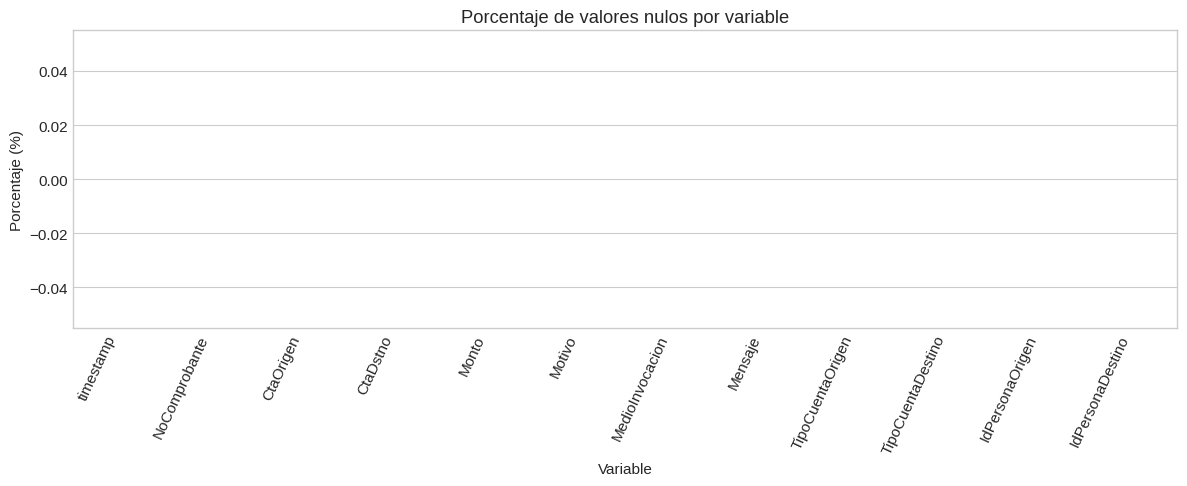

Evaluación de calidad de datos completada correctamente.


In [ ]:
# Crear copia para el análisis de calidad sin modificar df
df_calidad = df.copy()
df_calidad.columns = df_calidad.columns.astype(str).str.strip()

# Considerar como nulos los textos vacíos o compuestos solo por espacios
df_calidad = df_calidad.replace(r'^\s*$', pd.NA, regex=True)

# Tabla general de calidad
calidad = pd.DataFrame({
    'tipo': df_calidad.dtypes.astype(str),
    'nulos': df_calidad.isna().sum(),
    'porcentaje_nulos': df_calidad.isna().mean().mul(100),
    'unicos': df_calidad.nunique(dropna=True)
}).sort_values('porcentaje_nulos', ascending=False)

display(calidad.style.format({'porcentaje_nulos': '{:.2f}%'}))

# Duplicados exactos
duplicados_exactos = int(df_calidad.duplicated().sum())
pct_duplicados = duplicados_exactos / len(df_calidad) * 100 if len(df_calidad) > 0 else 0

# Comprobantes repetidos, sin contar valores nulos
comprobantes_validos = df_calidad[df_calidad['NoComprobante'].notna()].copy()
duplicados_comprobante = int(comprobantes_validos.duplicated(subset=['NoComprobante'], keep=False).sum())
pct_duplicados_comprobante = duplicados_comprobante / len(comprobantes_validos) * 100 if len(comprobantes_validos) > 0 else 0

print(f'Duplicados exactos: {duplicados_exactos:,} ({pct_duplicados:.4f}%)')
print(f'Registros con comprobante repetido: {duplicados_comprobante:,} ({pct_duplicados_comprobante:.4f}%)')

# Revisar montos
montos_numericos = pd.to_numeric(df_calidad['Monto'], errors='coerce')
montos_no_convertibles = int(montos_numericos.isna().sum() - df_calidad['Monto'].isna().sum())
montos_negativos = int((montos_numericos < 0).sum())
montos_cero = int((montos_numericos == 0).sum())

# Revisar fechas
fechas_convertidas = pd.to_datetime(df_calidad['timestamp'], errors='coerce', dayfirst=True)
fechas_no_convertibles = int(fechas_convertidas.isna().sum() - df_calidad['timestamp'].isna().sum())

# Revisar cuentas faltantes
cuentas_origen_nulas = int(df_calidad['CtaOrigen'].isna().sum())
cuentas_destino_nulas = int(df_calidad['CtaDstno'].isna().sum())

# Tabla de inconsistencias
inconsistencias = pd.DataFrame({
    'inconsistencia': [
        'Duplicados exactos',
        'Registros con comprobante repetido',
        'Montos no convertibles a número',
        'Montos negativos',
        'Montos iguales a cero',
        'Fechas no convertibles',
        'Cuentas de origen nulas',
        'Cuentas de destino nulas'
    ],
    'cantidad': [
        duplicados_exactos,
        duplicados_comprobante,
        montos_no_convertibles,
        montos_negativos,
        montos_cero,
        fechas_no_convertibles,
        cuentas_origen_nulas,
        cuentas_destino_nulas
    ]
})

inconsistencias['porcentaje'] = inconsistencias['cantidad'] / len(df_calidad) * 100

print('\nResumen de inconsistencias:')
display(inconsistencias.style.format({'porcentaje': '{:.4f}%'}))

# Gráfico de nulos
plt.figure(figsize=(12, 5))
sns.barplot(x=calidad.index, y=calidad['porcentaje_nulos'], color='#4C78A8')
plt.title('Porcentaje de valores nulos por variable')
plt.ylabel('Porcentaje (%)')
plt.xlabel('Variable')
plt.xticks(rotation=65, ha='right')
plt.tight_layout()
plt.show()

print('Evaluación de calidad de datos completada correctamente.')

## 6. Conversión de tipos y exploración descriptiva

Las conversiones se realizan sobre una copia denominada `df_modelo`, conservando intacto el DataFrame original `df`. La fecha se convierte a formato datetime, el monto a formato numérico y las variables textuales se normalizan únicamente eliminando espacios accidentales. Los identificadores ficticios no se cifran, reemplazan ni modifican.

In [ ]:
# 6. CONVERSIÓN DE TIPOS Y EXPLORACIÓN DESCRIPTIVA

# Verificar que df exista
if 'df' not in globals():
    raise NameError(
        "No existe 'df'. Ejecuta primero la carga del CSV."
    )

# Crear copia para el análisis y modelado
df_modelo = df.copy()
df_modelo.columns = df_modelo.columns.astype(str).str.strip()

# Guardar tipos originales
tipos_antes = df_modelo.dtypes.astype(str)

# ------------------------------------------------------------
# 1. CONVERTIR LA FECHA
# ------------------------------------------------------------

texto_fecha = (
    df_modelo['timestamp']
    .astype('string')
    .str.strip()
    .str.replace(
        r'(?i)a\.\s*m\.',
        'AM',
        regex=True
    )
    .str.replace(
        r'(?i)p\.\s*m\.',
        'PM',
        regex=True
    )
)

try:
    df_modelo['timestamp_dt'] = pd.to_datetime(
        texto_fecha,
        errors='coerce',
        dayfirst=True,
        format='mixed'
    )
except TypeError:
    df_modelo['timestamp_dt'] = pd.to_datetime(
        texto_fecha,
        errors='coerce',
        dayfirst=True
    )

# ------------------------------------------------------------
# 2. CONVERTIR EL MONTO
# ------------------------------------------------------------

def convertir_monto(valor):
    if pd.isna(valor):
        return np.nan

    if isinstance(
        valor,
        (int, float, np.integer, np.floating)
    ):
        return float(valor)

    texto = (
        str(valor)
        .strip()
        .replace('$', '')
        .replace(' ', '')
    )

    if texto == '':
        return np.nan

    # Cuando existen punto y coma, el último separador
    # se considera el separador decimal
    if ',' in texto and '.' in texto:
        if texto.rfind(',') > texto.rfind('.'):
            texto = (
                texto
                .replace('.', '')
                .replace(',', '.')
            )
        else:
            texto = texto.replace(',', '')

    elif ',' in texto:
        texto = texto.replace(',', '.')

    try:
        return float(texto)
    except ValueError:
        return np.nan

df_modelo['Monto'] = (
    df_modelo['Monto']
    .apply(convertir_monto)
)

# ------------------------------------------------------------
# 3. CONSERVAR IDENTIFICADORES COMO TEXTO
# ------------------------------------------------------------

columnas_identificadores = [
    'NoComprobante',
    'CtaOrigen',
    'CtaDstno',
    'IdPersonaOrigen',
    'IdPersonaDestino'
]

for columna in columnas_identificadores:
    if columna in df_modelo.columns:
        df_modelo[columna] = (
            df_modelo[columna]
            .astype('string')
            .str.strip()
        )

# ------------------------------------------------------------
# 4. NORMALIZAR VARIABLES CATEGÓRICAS
# ------------------------------------------------------------

columnas_categoricas = [
    'Motivo',
    'MedioInvocacion',
    'Mensaje',
    'TipoCuentaOrigen',
    'TipoCuentaDestino'
]

for columna in columnas_categoricas:
    if columna in df_modelo.columns:
        df_modelo[columna] = (
            df_modelo[columna]
            .astype('string')
            .str.strip()
        )

# ------------------------------------------------------------
# 5. COMPARAR TIPOS ANTES Y DESPUÉS
# ------------------------------------------------------------

comparacion_tipos = pd.DataFrame({
    'tipo_original': tipos_antes,
    'tipo_convertido': [
        str(df_modelo[columna].dtype)
        for columna in df.columns
    ]
})

display(comparacion_tipos)

# ------------------------------------------------------------
# 6. MOSTRAR RESULTADOS DE LAS CONVERSIONES
# ------------------------------------------------------------

fechas_validas = int(
    df_modelo['timestamp_dt']
    .notna()
    .sum()
)

fechas_no_convertidas = int(
    df_modelo['timestamp_dt']
    .isna()
    .sum()
)

montos_validos = int(
    df_modelo['Monto']
    .notna()
    .sum()
)

montos_no_convertidos = int(
    df_modelo['Monto']
    .isna()
    .sum()
)

print(
    f'Fechas convertidas correctamente: '
    f'{fechas_validas:,}'
)

print(
    f'Fechas no convertidas: '
    f'{fechas_no_convertidas:,}'
)

print(
    f'Montos convertidos correctamente: '
    f'{montos_validos:,}'
)

print(
    f'Montos no convertidos: '
    f'{montos_no_convertidos:,}'
)

print(
    f'Periodo identificado: '
    f'{df_modelo["timestamp_dt"].min()} '
    f'hasta '
    f'{df_modelo["timestamp_dt"].max()}'
)

# ------------------------------------------------------------
# 7. ESTADÍSTICAS DESCRIPTIVAS DEL MONTO
# ------------------------------------------------------------

print('\nEstadísticas descriptivas del monto:')

estadisticas_monto = (
    df_modelo['Monto']
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
    .to_frame(
        name='Monto'
    )
)

display(estadisticas_monto)

# ------------------------------------------------------------
# 8. ESTADÍSTICAS DE VARIABLES CATEGÓRICAS
# ------------------------------------------------------------

categoricas_disponibles = [
    columna
    for columna in columnas_categoricas
    if columna in df_modelo.columns
]

estadisticas_categoricas = (
    df_modelo[
        categoricas_disponibles
    ]
    .describe(
        include='all'
    )
    .T
)

display(estadisticas_categoricas)

# ------------------------------------------------------------
# 9. RESUMEN DE CARDINALIDAD
# ------------------------------------------------------------

cardinalidad = pd.DataFrame({
    'variable': df_modelo.columns,
    'valores_unicos': [
        df_modelo[columna].nunique(
            dropna=True
        )
        for columna in df_modelo.columns
    ]
}).sort_values(
    by='valores_unicos',
    ascending=False
)

display(cardinalidad)

# ------------------------------------------------------------
# 10. VISTA PREVIA DEL RESULTADO
# ------------------------------------------------------------

columnas_vista = [
    'timestamp',
    'timestamp_dt',
    'NoComprobante',
    'CtaOrigen',
    'CtaDstno',
    'Monto',
    'MedioInvocacion',
    'TipoCuentaOrigen',
    'TipoCuentaDestino'
]

columnas_vista = [
    columna
    for columna in columnas_vista
    if columna in df_modelo.columns
]

display(
    df_modelo[
        columnas_vista
    ].head(10)
)

print(
    'Conversión de tipos y exploración '
    'descriptiva completadas correctamente.'
)

,tipo_original,tipo_convertido
timestamp,object,object
NoComprobante,object,string
CtaOrigen,object,string
CtaDstno,object,string
Monto,object,float64
Motivo,object,string
MedioInvocacion,object,string
Mensaje,object,string
TipoCuentaOrigen,object,string
TipoCuentaDestino,object,string


Fechas convertidas correctamente: 462,439
Fechas no convertidas: 0
Montos convertidos correctamente: 462,439
Montos no convertidos: 0
Periodo identificado: 2026-06-22 00:00:31 hasta 2026-08-24 22:44:49

Estadísticas descriptivas del monto:


,Monto
count,"462,439.00"
mean,221.87
std,"2,433.48"
min,0.01
25%,5.00
50%,20.00
75%,80.00
90%,251.00
95%,570.00
99%,"3,700.00"


,count,unique,top,freq
Motivo,462439,47777,Transf Terceros,349587
MedioInvocacion,462439,2,APP.MOVIL,457172
Mensaje,462439,20,TRANSACCIÓN EXITOSA,456481
TipoCuentaOrigen,462439,4,CuentaAhorro,387390
TipoCuentaDestino,462439,7,CUENTA DE AHORROS,406432


,variable,valores_unicos
1,NoComprobante,456453
0,timestamp,411389
12,timestamp_dt,411389
2,CtaOrigen,76398
3,CtaDstno,71628
10,IdPersonaOrigen,62212
11,IdPersonaDestino,57737
5,Motivo,47777
4,Monto,21187
7,Mensaje,20


,timestamp,timestamp_dt,NoComprobante,CtaOrigen,CtaDstno,Monto,MedioInvocacion,TipoCuentaOrigen,TipoCuentaDestino
0,"22/8/2026, 5:18:45 a.m.",2026-08-22 05:18:45,pago_2947382431,cue_1513654255,cue_853007743,149.00,APP.MOVIL,CuentaCorriente,CUENTA DE AHORROS
1,"22/8/2026, 5:15:54 a.m.",2026-08-22 05:15:54,pago_3153404361,cue_2080926275,cue_1025269289,"2,000.00",BANCA.WEB,CuentaAhorro,CUENTA DE AHORROS
2,"22/8/2026, 5:16:06 a.m.",2026-08-22 05:16:06,pago_586969203,cue_2092819066,cue_199297968,10.00,APP.MOVIL,CuentaAhorro,CUENTA DE AHORROS
3,"22/8/2026, 5:12:05 a.m.",2026-08-22 05:12:05,pago_1026741020,cue_1513654255,cue_3010592661,150.00,APP.MOVIL,CuentaCorriente,CUENTA DE AHORROS
4,"22/8/2026, 5:13:29 a.m.",2026-08-22 05:13:29,pago_783275908,cue_1069924004,cue_2471242006,20.00,APP.MOVIL,AhorroListo,CUENTA DE AHORROS
5,"22/8/2026, 5:06:58 a.m.",2026-08-22 05:06:58,pago_1844626254,cue_458877120,cue_1602594591,10.00,APP.MOVIL,CuentaAhorro,CUENTA DE AHORROS
6,"22/8/2026, 5:07:24 a.m.",2026-08-22 05:07:24,pago_1788806999,cue_1914688142,cue_4238831370,263.44,APP.MOVIL,CuentaAhorro,CUENTA DE AHORROS
7,"22/8/2026, 5:03:01 a.m.",2026-08-22 05:03:01,pago_3379294078,cue_1914688142,cue_314832020,263.44,APP.MOVIL,CuentaAhorro,CUENTA DE AHORROS
8,"22/8/2026, 5:04:48 a.m.",2026-08-22 05:04:48,pago_2454561592,cue_1914688142,cue_3894025361,263.44,APP.MOVIL,CuentaAhorro,CUENTA DE AHORROS
9,"22/8/2026, 4:58:45 a.m.",2026-08-22 04:58:45,pago_85340277,cue_1914688142,cue_618504287,263.44,APP.MOVIL,CuentaAhorro,CUENTA DE AHORROS


Conversión de tipos y exploración descriptiva completadas correctamente.


### Interpretación

El conjunto contiene 462.439 transferencias registradas entre junio y agosto de 2026, sin errores en la conversión de fechas y montos. El monto promedio es USD 221,87, pero la mediana es USD 20,00, lo que evidencia que predominan las operaciones pequeñas y existen algunos valores muy elevados. La aplicación móvil, las transferencias a terceros y las cuentas de ahorro son las categorías predominantes. Por ello, se analizarán los valores atípicos y se construirán perfiles agrupados por cuenta de origen.

## 7. Analisis exploratorio y visualizaciones

---



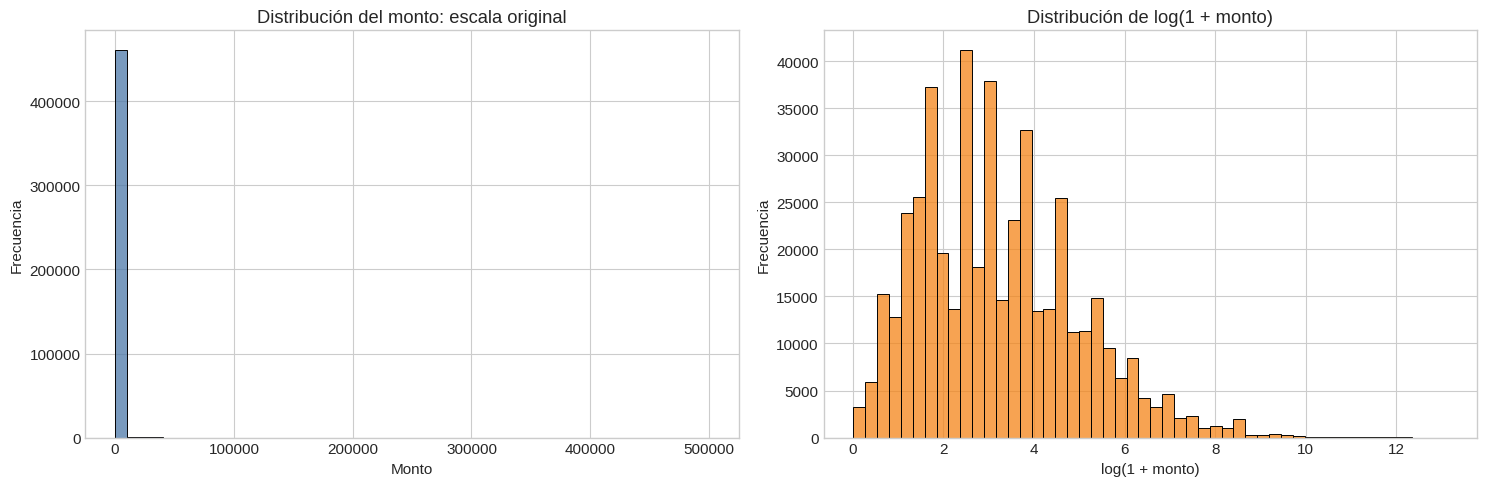

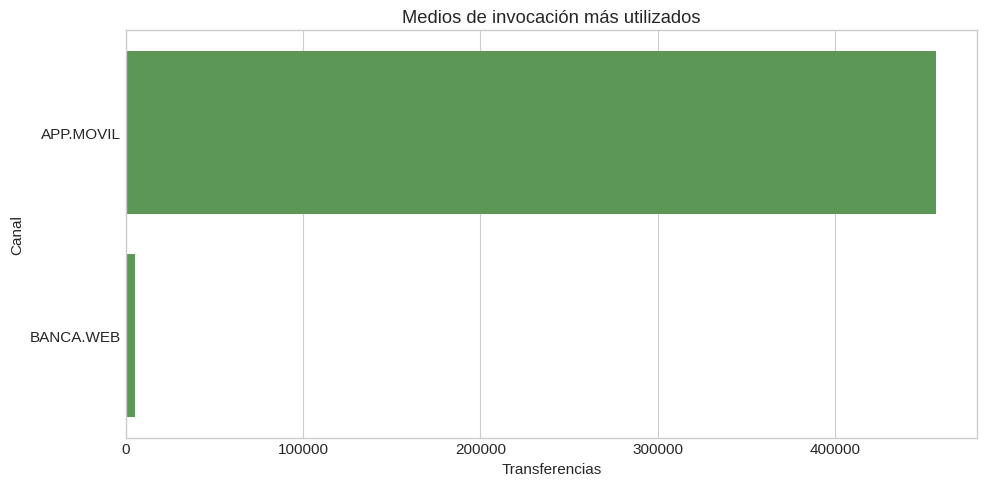

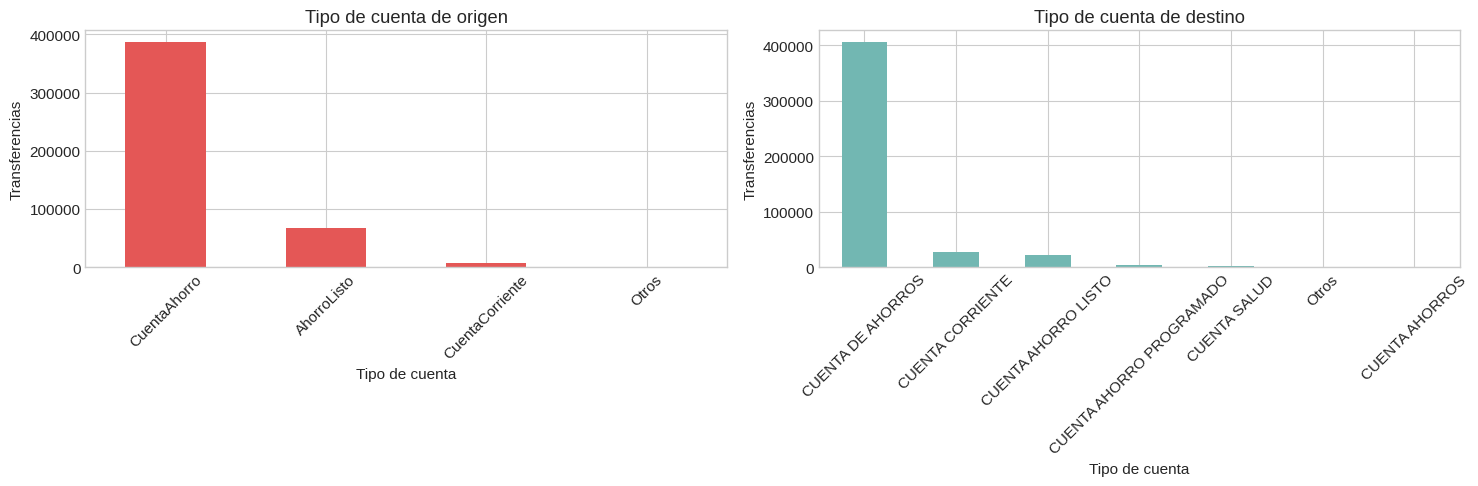

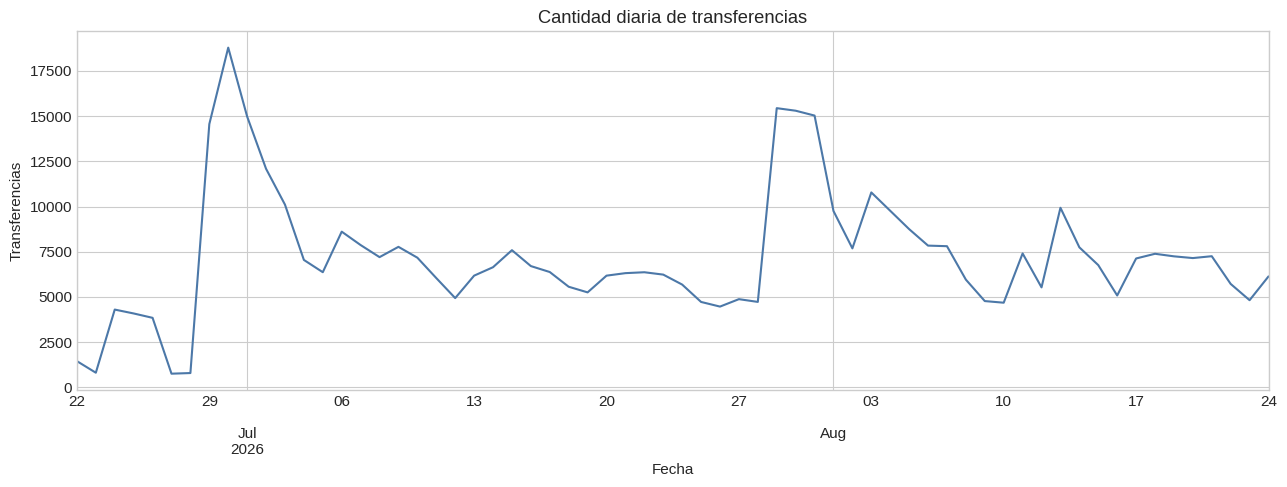

RESUMEN EXPLORATORIO
Montos positivos analizados: 462,439
Canal más utilizado: APP.MOVIL
Día con mayor actividad: 2026-06-30
Máximo diario: 18,792 transferencias


In [ ]:
## 7. Análisis exploratorio y visualizaciones

if 'df_modelo' not in globals():
    raise NameError("No existe 'df_modelo'. Ejecuta primero la sección 6.")

columnas_necesarias = ['Monto','MedioInvocacion','TipoCuentaOrigen','TipoCuentaDestino','timestamp_dt']
columnas_faltantes = [c for c in columnas_necesarias if c not in df_modelo.columns]
if columnas_faltantes:
    raise ValueError(f'Faltan columnas necesarias: {columnas_faltantes}')

# Visualización 1: distribución del monto
montos_validos = df_modelo.loc[df_modelo['Monto'].notna() & df_modelo['Monto'].gt(0),'Monto']
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(montos_validos, bins=50, ax=axes[0], color='#4C78A8')
axes[0].set(title='Distribución del monto: escala original', xlabel='Monto', ylabel='Frecuencia')
sns.histplot(np.log1p(montos_validos), bins=50, ax=axes[1], color='#F58518')
axes[1].set(title='Distribución de log(1 + monto)', xlabel='log(1 + monto)', ylabel='Frecuencia')
plt.tight_layout(); plt.show()

# Visualización 2: canales más utilizados
orden_canal = df_modelo['MedioInvocacion'].fillna('Desconocido').value_counts().head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=orden_canal.values, y=orden_canal.index, color='#54A24B')
plt.title('Medios de invocación más utilizados'); plt.xlabel('Transferencias'); plt.ylabel('Canal')
plt.tight_layout(); plt.show()

# Visualización 3: tipos de cuenta
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
df_modelo['TipoCuentaOrigen'].fillna('Desconocido').value_counts().plot(kind='bar', ax=axes[0], color='#E45756')
axes[0].set(title='Tipo de cuenta de origen', xlabel='Tipo de cuenta', ylabel='Transferencias'); axes[0].tick_params(axis='x', rotation=45)
df_modelo['TipoCuentaDestino'].fillna('Desconocido').value_counts().plot(kind='bar', ax=axes[1], color='#72B7B2')
axes[1].set(title='Tipo de cuenta de destino', xlabel='Tipo de cuenta', ylabel='Transferencias'); axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

# Visualización 4: volumen diario
serie_diaria = df_modelo.dropna(subset=['timestamp_dt']).set_index('timestamp_dt').resample('D').size()
plt.figure(figsize=(13, 5)); serie_diaria.plot(color='#4C78A8')
plt.title('Cantidad diaria de transferencias'); plt.ylabel('Transferencias'); plt.xlabel('Fecha')
plt.tight_layout(); plt.show()

print('RESUMEN EXPLORATORIO')
print(f'Montos positivos analizados: {len(montos_validos):,}')
print(f'Canal más utilizado: {orden_canal.index[0]}')
print(f'Día con mayor actividad: {serie_diaria.idxmax():%Y-%m-%d}')
print(f'Máximo diario: {int(serie_diaria.max()):,} transferencias')

### Interpretación

Se analizaron 462.439 transferencias con montos positivos. La aplicación móvil fue el canal predominante. La actividad diaria presentó variaciones importantes y alcanzó su punto máximo el 30 de junio de 2026, con 18.792 transferencias; este incremento debe considerarse al analizar patrones atípicos, aunque por sí solo no representa una anomalía.

In [ ]:
print('TIPOS DE CUENTA DE ORIGEN')
display(df_modelo['TipoCuentaOrigen'].value_counts(dropna=False).rename_axis('tipo').reset_index(name='cantidad'))

print('TIPOS DE CUENTA DE DESTINO')
display(df_modelo['TipoCuentaDestino'].value_counts(dropna=False).rename_axis('tipo').reset_index(name='cantidad'))

TIPOS DE CUENTA DE ORIGEN


,tipo,cantidad
0,CuentaAhorro,387390
1,AhorroListo,67908
2,CuentaCorriente,7084
3,Otros,57


TIPOS DE CUENTA DE DESTINO


,tipo,cantidad
0,CUENTA DE AHORROS,406432
1,CUENTA CORRIENTE,27662
2,CUENTA AHORRO LISTO,21873
3,CUENTA AHORRO PROGRAMADO,4347
4,CUENTA SALUD,1851
5,Otros,273
6,CUENTA AHORROS,1


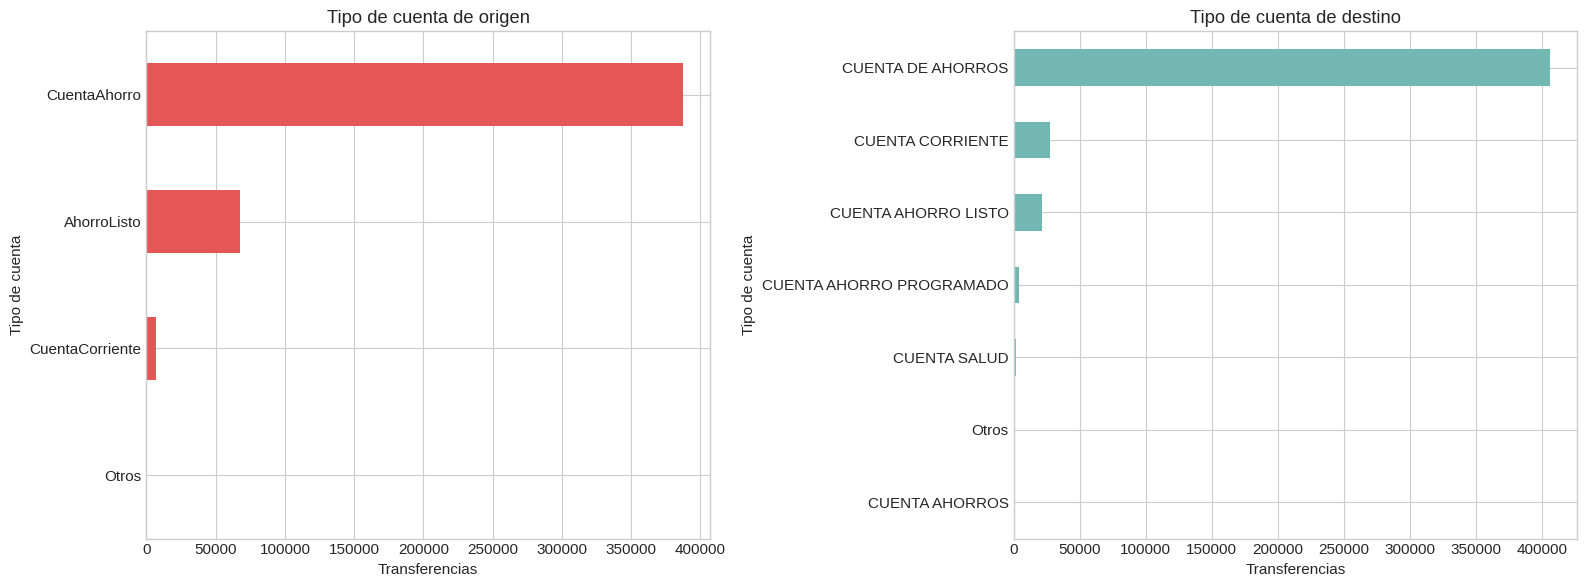

In [ ]:
# Visualización 3 corregida: tipos de cuenta
conteo_origen = df_modelo['TipoCuentaOrigen'].fillna('Desconocido').value_counts().sort_values()
conteo_destino = df_modelo['TipoCuentaDestino'].fillna('Desconocido').value_counts().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
conteo_origen.plot(kind='barh', ax=axes[0], color='#E45756')
axes[0].set(title='Tipo de cuenta de origen', xlabel='Transferencias', ylabel='Tipo de cuenta')
conteo_destino.plot(kind='barh', ax=axes[1], color='#72B7B2')
axes[1].set(title='Tipo de cuenta de destino', xlabel='Transferencias', ylabel='Tipo de cuenta')
plt.tight_layout(); plt.show()

### Interpretación

La mayoría de las transferencias se realizan desde **cuentas de ahorro** y también se dirigen principalmente hacia este tipo de cuenta. Las cuentas **Ahorro Listo** y **Corriente** presentan una participación considerablemente menor, mientras que los demás tipos registran poca actividad.

Además, en las cuentas de destino aparece **“CUENTA DE AHORROS”** dos veces. Esto probablemente se debe a diferencias de escritura, espacios o caracteres ocultos. Por esta razón, es necesario unificar los nombres antes del modelado, evitando que una misma categoría sea tratada como dos tipos de cuenta diferentes.

## 8. Identificacion de valores atipicos

Se utiliza el criterio IQR para documentar montos atipicos. Estos registros **no se eliminan automaticamente**, porque un monto alto puede ser una transferencia valida y ademas aporta informacion relevante para la deteccion de comportamientos inusuales. Para reducir la asimetria se empleara `log1p`.

RESULTADOS DEL MÉTODO IQR
Primer cuartil (Q1): USD 5.00
Tercer cuartil (Q3): USD 80.00
Rango intercuartílico: USD 75.00
Límite inferior: USD 0.00
Límite superior: USD 192.50
Montos atípicos: 59,632 (12.90%)


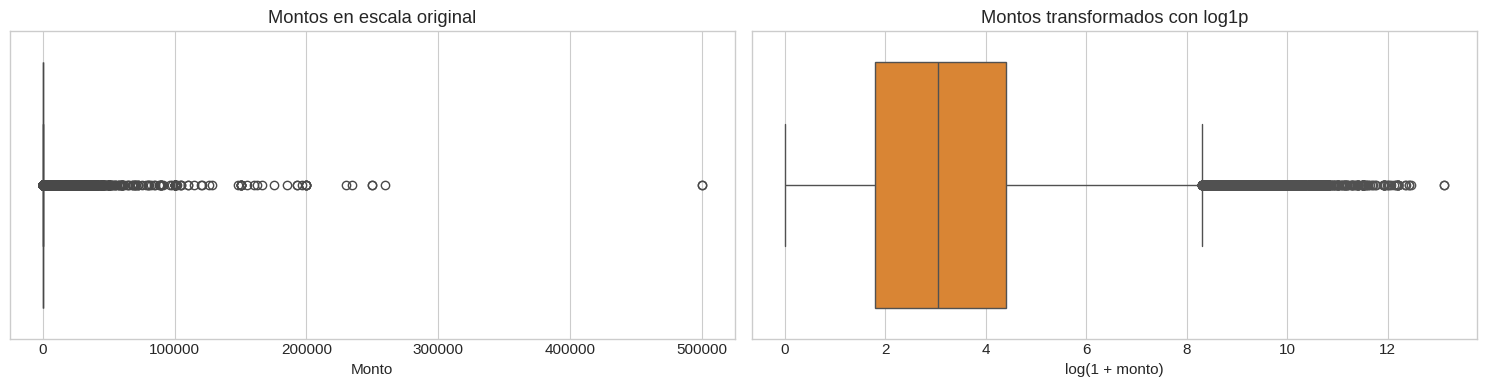

,timestamp,NoComprobante,CtaOrigen,CtaDstno,Monto
201146,"31/7/2026, 4:56:11 p.m.",pago_1164905254,cue_4051472758,cue_486672820,"500,000.00"
256414,"31/7/2026, 4:57:23 p.m.",pago_3108585929,cue_4051472758,cue_2395365557,"500,000.00"
175787,"23/7/2026, 1:59:18 p.m.",pago_401133915,cue_1472150705,cue_25888861,"260,000.00"
421581,"24/6/2026, 12:17:51 a.m.",pago_3986305932,cue_2082313178,cue_3551535924,"250,000.00"
211997,"23/7/2026, 2:56:04 p.m.",pago_3618576220,cue_2769819142,cue_3326884124,"250,000.00"
397734,"2/7/2026, 12:51:22 p.m.",pago_3731196249,cue_2354586364,cue_544739220,"235,000.00"
399715,"3/7/2026, 9:22:24 a.m.",pago_422784550,cue_3336003200,cue_794730949,"230,000.00"
331711,"6/7/2026, 1:09:46 p.m.",pago_3293894048,cue_948833010,cue_4175150188,"200,000.00"
222802,"31/7/2026, 1:50:03 p.m.",pago_1247977193,cue_2688025679,cue_2507229708,"200,000.00"
310788,"9/7/2026, 9:42:46 a.m.",pago_21628544,cue_3349832612,cue_1593807017,"200,000.00"


In [ ]:
# 8. IDENTIFICACIÓN DE VALORES ATÍPICOS

if 'df_modelo' not in globals():
    raise NameError("No existe 'df_modelo'. Ejecuta primero la sección 7.")

montos_validos = df_modelo.loc[df_modelo['Monto'].notna() & df_modelo['Monto'].gt(0),'Monto']
if montos_validos.empty:
    raise ValueError('No existen montos positivos para analizar.')

q1 = montos_validos.quantile(0.25)
q3 = montos_validos.quantile(0.75)
iqr = q3 - q1
limite_inferior = max(0, q1 - 1.5 * iqr)
limite_superior = q3 + 1.5 * iqr

df_modelo['monto_atipico_iqr'] = ((df_modelo['Monto'] < limite_inferior) | (df_modelo['Monto'] > limite_superior)).astype(int)
n_atipicos = int(df_modelo['monto_atipico_iqr'].sum())
pct_atipicos = n_atipicos / len(montos_validos) * 100

print('RESULTADOS DEL MÉTODO IQR')
print(f'Primer cuartil (Q1): USD {q1:,.2f}')
print(f'Tercer cuartil (Q3): USD {q3:,.2f}')
print(f'Rango intercuartílico: USD {iqr:,.2f}')
print(f'Límite inferior: USD {limite_inferior:,.2f}')
print(f'Límite superior: USD {limite_superior:,.2f}')
print(f'Montos atípicos: {n_atipicos:,} ({pct_atipicos:.2f}%)')

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.boxplot(x=montos_validos, ax=axes[0], color='#4C78A8')
axes[0].set(title='Montos en escala original', xlabel='Monto')
sns.boxplot(x=np.log1p(montos_validos), ax=axes[1], color='#F58518')
axes[1].set(title='Montos transformados con log1p', xlabel='log(1 + monto)')
plt.tight_layout(); plt.show()

display(df_modelo.loc[df_modelo['monto_atipico_iqr'].eq(1),['timestamp','NoComprobante','CtaOrigen','CtaDstno','Monto']].sort_values('Monto', ascending=False).head(10))

### Interpretación

La mayoría de las transferencias tiene montos bajos. Sin embargo, 59.632 operaciones superan los USD 192,50 y por eso se consideran valores atípicos. La primera gráfica se ve muy comprimida porque existen montos extremadamente altos, incluso de USD 500.000. La segunda gráfica reduce visualmente esas diferencias y permite observar mejor cómo se distribuyen los montos. Estas operaciones no se eliminarán porque pueden ser válidas y serán útiles para identificar cuentas con comportamientos poco comunes.

## 9. Limpieza y feature engineering

In [ ]:
# 9. LIMPIEZA Y FEATURE ENGINEERING

if 'df_modelo' not in globals():
    raise NameError("No existe 'df_modelo'. Ejecuta primero las secciones anteriores.")

df_modelo = df_modelo.copy()
df_modelo.columns = df_modelo.columns.astype(str).str.strip()
registro_limpieza = []

columnas_indispensables = ['CtaOrigen','CtaDstno','Monto','timestamp','TipoCuentaOrigen','TipoCuentaDestino']
faltantes = [c for c in columnas_indispensables if c not in df_modelo.columns]
if faltantes:
    raise ValueError(f'Faltan columnas indispensables: {faltantes}')

# Eliminar duplicados exactos
antes = len(df_modelo)
df_modelo = df_modelo.drop_duplicates().copy()
registro_limpieza.append(['Duplicados exactos',antes-len(df_modelo),'Eliminados'])

# Convertir monto y eliminar registros indispensables inválidos
df_modelo['Monto'] = pd.to_numeric(df_modelo['Monto'], errors='coerce')
antes = len(df_modelo)
df_modelo = df_modelo.dropna(subset=['CtaOrigen','Monto']).copy()
df_modelo = df_modelo[df_modelo['Monto'] >= 0].copy()
registro_limpieza.append(['Cuenta de origen o monto inválido',antes-len(df_modelo),'Eliminados'])

# Limpiar identificadores
for columna in ['CtaOrigen','CtaDstno','NoComprobante','IdPersonaOrigen','IdPersonaDestino']:
    if columna in df_modelo.columns:
        df_modelo[columna] = df_modelo[columna].astype('string').str.strip()

antes = len(df_modelo)
df_modelo = df_modelo[df_modelo['CtaOrigen'].notna() & df_modelo['CtaOrigen'].ne('')].copy()
registro_limpieza.append(['Cuentas de origen vacías',antes-len(df_modelo),'Eliminadas'])

# Tratar categorías faltantes
columnas_categoricas = ['Motivo','MedioInvocacion','Mensaje','TipoCuentaOrigen','TipoCuentaDestino']
for columna in columnas_categoricas:
    if columna in df_modelo.columns:
        nulos_antes = int(df_modelo[columna].isna().sum() + df_modelo[columna].astype(str).str.strip().eq('').sum())
        df_modelo[columna] = df_modelo[columna].fillna('Desconocido').astype(str).str.strip().replace('','Desconocido')
        registro_limpieza.append([f'Nulos o vacíos de {columna}',nulos_antes,"Reemplazados por 'Desconocido'"])

# Preparar fecha si todavía no existe
if 'timestamp_dt' not in df_modelo.columns:
    texto_fecha = df_modelo['timestamp'].astype(str).str.strip()
    texto_fecha = texto_fecha.str.replace(r'(?i)a\.\s*m\.','AM',regex=True).str.replace(r'(?i)p\.\s*m\.','PM',regex=True)
    df_modelo['timestamp_dt'] = pd.to_datetime(texto_fecha, errors='coerce', dayfirst=True)

fechas_invalidas = int(df_modelo['timestamp_dt'].isna().sum())
registro_limpieza.append(['Fechas no convertidas',fechas_invalidas,'Conservadas como nulas'])

# Variables temporales derivadas
df_modelo['hora'] = df_modelo['timestamp_dt'].dt.hour
df_modelo['dia_semana'] = df_modelo['timestamp_dt'].dt.dayofweek
df_modelo['es_fin_semana'] = df_modelo['dia_semana'].isin([5,6]).astype(int)
df_modelo.loc[df_modelo['timestamp_dt'].isna(),'es_fin_semana'] = np.nan
df_modelo['es_nocturna'] = df_modelo['hora'].isin([0,1,2,3,4,5,22,23]).astype(int)
df_modelo.loc[df_modelo['timestamp_dt'].isna(),'es_nocturna'] = np.nan

# Transformación del monto y conservación del indicador IQR
df_modelo['monto_log'] = np.log1p(df_modelo['Monto'].clip(lower=0))
if 'limite_inferior' not in globals() or 'limite_superior' not in globals():
    q1, q3 = df_modelo['Monto'].quantile([0.25,0.75])
    iqr = q3-q1
    limite_inferior = max(0,q1-1.5*iqr)
    limite_superior = q3+1.5*iqr
df_modelo['monto_atipico_iqr'] = ((df_modelo['Monto'] < limite_inferior) | (df_modelo['Monto'] > limite_superior)).astype(int)

# Canal móvil y variables adicionales
df_modelo['es_canal_movil'] = df_modelo['MedioInvocacion'].str.contains('movil|móvil|mobile|app',case=False,na=False,regex=True).astype(int)
df_modelo['tipo_flujo'] = df_modelo['TipoCuentaOrigen']+'_A_'+df_modelo['TipoCuentaDestino']
df_modelo['franja_horaria'] = pd.cut(df_modelo['hora'],bins=[-1,5,11,17,21,23],labels=['Madrugada','Mañana','Tarde','Noche','Noche tardía'])

# Mostrar resultados
tabla_limpieza = pd.DataFrame(registro_limpieza,columns=['tratamiento','registros_afectados','decision'])
display(tabla_limpieza)
print(f'Dimensiones después de la limpieza: {df_modelo.shape[0]:,} registros x {df_modelo.shape[1]} variables')

variables_derivadas = ['hora','dia_semana','es_fin_semana','es_nocturna','monto_log','monto_atipico_iqr','es_canal_movil','tipo_flujo','franja_horaria']
display(df_modelo[variables_derivadas].head(10))
print('Limpieza y creación de variables derivadas completadas correctamente.')

,tratamiento,registros_afectados,decision
0,Duplicados exactos,0,Eliminados
1,Cuenta de origen o monto inválido,0,Eliminados
2,Cuentas de origen vacías,0,Eliminadas
3,Nulos o vacíos de Motivo,0,Reemplazados por 'Desconocido'
4,Nulos o vacíos de MedioInvocacion,0,Reemplazados por 'Desconocido'
5,Nulos o vacíos de Mensaje,0,Reemplazados por 'Desconocido'
6,Nulos o vacíos de TipoCuentaOrigen,0,Reemplazados por 'Desconocido'
7,Nulos o vacíos de TipoCuentaDestino,0,Reemplazados por 'Desconocido'
8,Fechas no convertidas,0,Conservadas como nulas


Dimensiones después de la limpieza: 462,439 registros x 22 variables


,hora,dia_semana,es_fin_semana,es_nocturna,monto_log,monto_atipico_iqr,es_canal_movil,tipo_flujo,franja_horaria
0,5,5,1.00,1.00,5.01,0,1,CuentaCorriente_A_CUENTA DE AHORROS,Madrugada
1,5,5,1.00,1.00,7.60,1,0,CuentaAhorro_A_CUENTA DE AHORROS,Madrugada
2,5,5,1.00,1.00,2.40,0,1,CuentaAhorro_A_CUENTA DE AHORROS,Madrugada
3,5,5,1.00,1.00,5.02,0,1,CuentaCorriente_A_CUENTA DE AHORROS,Madrugada
4,5,5,1.00,1.00,3.04,0,1,AhorroListo_A_CUENTA DE AHORROS,Madrugada
5,5,5,1.00,1.00,2.40,0,1,CuentaAhorro_A_CUENTA DE AHORROS,Madrugada
6,5,5,1.00,1.00,5.58,1,1,CuentaAhorro_A_CUENTA DE AHORROS,Madrugada
7,5,5,1.00,1.00,5.58,1,1,CuentaAhorro_A_CUENTA DE AHORROS,Madrugada
8,5,5,1.00,1.00,5.58,1,1,CuentaAhorro_A_CUENTA DE AHORROS,Madrugada
9,4,5,1.00,1.00,5.58,1,1,CuentaAhorro_A_CUENTA DE AHORROS,Madrugada


Limpieza y creación de variables derivadas completadas correctamente.


### Interpretación

No se encontraron duplicados, datos indispensables inválidos, categorías vacías ni fechas incorrectas; por eso se conservaron las 462.439 transferencias. El proceso agregó nuevas variables sobre horario, canal, tipo de cuenta y montos atípicos, aumentando el conjunto a 22 variables. Estas características permitirán describir mejor el comportamiento de cada cuenta en el modelado.

## 10. Construccion de perfiles por cuenta de origen

Esta etapa genera varias variables derivadas adicionales. Las cuentas se conservan exactamente como aparecen en el archivo, pues ya son ficticias. texto en negrita

In [ ]:
## 10. CONSTRUCCIÓN DE PERFILES POR CUENTA DE ORIGEN

if 'df_modelo' not in globals():
    raise NameError("No existe 'df_modelo'. Ejecuta primero la sección 9.")

columnas_necesarias = ['CtaOrigen','CtaDstno','Monto','timestamp_dt','es_fin_semana','es_nocturna','es_canal_movil','monto_atipico_iqr']
faltantes = [c for c in columnas_necesarias if c not in df_modelo.columns]
if faltantes:
    raise ValueError(f'Faltan columnas necesarias: {faltantes}')

def moda_segura(serie):
    moda = serie.dropna().mode()
    return moda.iloc[0] if not moda.empty else 'Desconocido'

df_perfil = df_modelo.groupby('CtaOrigen',as_index=False).agg(
    num_transferencias=('Monto','size'),
    monto_total=('Monto','sum'),
    monto_promedio=('Monto','mean'),
    monto_mediano=('Monto','median'),
    monto_minimo=('Monto','min'),
    monto_maximo=('Monto','max'),
    monto_desviacion=('Monto','std'),
    destinos_distintos=('CtaDstno','nunique'),
    dias_con_actividad=('timestamp_dt',lambda x: x.dt.date.nunique()),
    fecha_primera=('timestamp_dt','min'),
    fecha_ultima=('timestamp_dt','max'),
    pct_fin_semana=('es_fin_semana','mean'),
    pct_nocturnas=('es_nocturna','mean'),
    pct_canal_movil=('es_canal_movil','mean'),
    pct_montos_atipicos=('monto_atipico_iqr','mean'),
    canal_principal=('MedioInvocacion',moda_segura),
    tipo_cuenta_origen=('TipoCuentaOrigen',moda_segura),
    tipo_cuenta_destino_principal=('TipoCuentaDestino',moda_segura)
)

df_perfil['monto_desviacion'] = df_perfil['monto_desviacion'].fillna(0)
df_perfil['duracion_observada_dias'] = (df_perfil['fecha_ultima']-df_perfil['fecha_primera']).dt.days+1
df_perfil['duracion_observada_dias'] = df_perfil['duracion_observada_dias'].clip(lower=1)
df_perfil['transferencias_por_dia'] = df_perfil['num_transferencias']/df_perfil['dias_con_actividad'].clip(lower=1)
df_perfil['diversidad_destinos'] = df_perfil['destinos_distintos']/df_perfil['num_transferencias'].clip(lower=1)
df_perfil['coef_variacion_monto'] = df_perfil['monto_desviacion']/df_perfil['monto_promedio'].replace(0,np.nan)
df_perfil['coef_variacion_monto'] = df_perfil['coef_variacion_monto'].replace([np.inf,-np.inf],np.nan).fillna(0)

columnas_porcentaje = ['pct_fin_semana','pct_nocturnas','pct_canal_movil','pct_montos_atipicos']
df_perfil[columnas_porcentaje] = df_perfil[columnas_porcentaje].mul(100)

df_perfil['log_num_transferencias'] = np.log1p(df_perfil['num_transferencias'])
df_perfil['log_monto_total'] = np.log1p(df_perfil['monto_total'].clip(lower=0))
df_perfil['log_monto_promedio'] = np.log1p(df_perfil['monto_promedio'].clip(lower=0))
df_perfil['log_monto_maximo'] = np.log1p(df_perfil['monto_maximo'].clip(lower=0))
df_perfil['log_destinos_distintos'] = np.log1p(df_perfil['destinos_distintos'])

print(f'Cuentas de origen analizadas: {len(df_perfil):,}')
print(f'Variables creadas por perfil: {df_perfil.shape[1]}')
print(f'Promedio de transferencias por cuenta: {df_perfil["num_transferencias"].mean():,.2f}')
print(f'Mediana de transferencias por cuenta: {df_perfil["num_transferencias"].median():,.2f}')

display(df_perfil.head(10))
display(df_perfil[['num_transferencias','monto_total','monto_promedio','destinos_distintos','dias_con_actividad','transferencias_por_dia','pct_nocturnas','pct_canal_movil','pct_montos_atipicos']].describe().T)

Cuentas de origen analizadas: 76,398
Variables creadas por perfil: 28
Promedio de transferencias por cuenta: 6.05
Mediana de transferencias por cuenta: 3.00


,CtaOrigen,num_transferencias,monto_total,monto_promedio,monto_mediano,monto_minimo,monto_maximo,monto_desviacion,destinos_distintos,dias_con_actividad,fecha_primera,fecha_ultima,pct_fin_semana,pct_nocturnas,pct_canal_movil,pct_montos_atipicos,canal_principal,tipo_cuenta_origen,tipo_cuenta_destino_principal,duracion_observada_dias,transferencias_por_dia,diversidad_destinos,coef_variacion_monto,log_num_transferencias,log_monto_total,log_monto_promedio,log_monto_maximo,log_destinos_distintos
0,cue_1000018622,4,771.10,192.78,217.00,17.10,320.00,126.78,1,4,2026-06-29 22:36:22,2026-07-29 13:51:23,0.00,25.00,100.00,75.00,APP.MOVIL,CuentaAhorro,CUENTA DE AHORROS,30,1.00,0.25,0.66,1.61,6.65,5.27,5.77,0.69
1,cue_1000041683,8,"1,170.00",146.25,150.00,40.00,330.00,91.17,1,8,2026-06-27 13:39:49,2026-08-22 10:12:18,37.50,25.00,0.00,25.00,BANCA.WEB,CuentaCorriente,CUENTA DE AHORROS,56,1.00,0.12,0.62,2.20,7.07,4.99,5.80,0.69
2,cue_1000060212,1,10.00,10.00,10.00,10.00,10.00,0.00,1,1,2026-08-06 13:11:25,2026-08-06 13:11:25,0.00,0.00,100.00,0.00,APP.MOVIL,CuentaAhorro,CUENTA CORRIENTE,1,1.00,1.00,0.00,0.69,2.40,2.40,2.40,0.69
3,cue_1000089638,12,727.24,60.60,62.50,20.00,100.00,38.31,8,9,2026-07-09 18:25:37,2026-08-13 21:56:51,41.67,0.00,100.00,0.00,APP.MOVIL,CuentaAhorro,CUENTA DE AHORROS,36,1.33,0.67,0.63,2.56,6.59,4.12,4.62,2.20
4,cue_1000097609,1,3.00,3.00,3.00,3.00,3.00,0.00,1,1,2026-08-12 08:18:59,2026-08-12 08:18:59,0.00,0.00,100.00,0.00,APP.MOVIL,CuentaAhorro,CUENTA DE AHORROS,1,1.00,1.00,0.00,0.69,1.39,1.39,1.39,0.69
5,cue_1000121712,2,8.00,4.00,4.00,2.00,6.00,2.83,2,2,2026-06-24 15:10:59,2026-08-01 17:41:07,50.00,0.00,0.00,0.00,BANCA.WEB,CuentaAhorro,CUENTA DE AHORROS,39,1.00,1.00,0.71,1.10,2.20,1.61,1.95,1.10
6,cue_1000165278,8,310.65,38.83,35.25,0.75,120.00,40.81,4,5,2026-06-30 11:03:37,2026-08-01 17:33:52,12.50,0.00,100.00,0.00,APP.MOVIL,CuentaAhorro,CUENTA DE AHORROS,33,1.60,0.50,1.05,2.20,5.74,3.68,4.80,1.61
7,cue_1000176823,1,9.41,9.41,9.41,9.41,9.41,0.00,1,1,2026-08-11 13:17:12,2026-08-11 13:17:12,0.00,0.00,100.00,0.00,APP.MOVIL,CuentaAhorro,CUENTA DE AHORROS,1,1.00,1.00,0.00,0.69,2.34,2.34,2.34,0.69
8,cue_1000232010,2,431.36,215.68,215.68,6.36,425.00,296.02,2,2,2026-07-03 20:53:22,2026-08-10 14:22:20,0.00,0.00,0.00,50.00,BANCA.WEB,CuentaAhorro,CUENTA DE AHORROS,38,1.00,1.00,1.37,1.10,6.07,5.38,6.05,1.10
9,cue_1000261260,4,"5,000.00","1,250.00","1,000.00","1,000.00","2,000.00",500.00,1,4,2026-07-11 09:36:12,2026-08-03 13:31:52,50.00,0.00,100.00,100.00,APP.MOVIL,AhorroListo,CUENTA DE AHORROS,24,1.00,0.25,0.40,1.61,8.52,7.13,7.60,0.69


,count,mean,std,min,25%,50%,75%,max
num_transferencias,"76,398.00",6.05,10.95,1.00,1.00,3.00,7.00,955.00
monto_total,"76,398.00","1,342.98","8,718.25",0.01,48.00,200.00,643.94,"1,000,000.00"
monto_promedio,"76,398.00",401.27,"3,637.50",0.01,16.97,46.67,138.81,"500,000.00"
destinos_distintos,"76,398.00",2.99,3.62,1.00,1.00,2.00,4.00,193.00
dias_con_actividad,"76,398.00",4.61,5.04,1.00,1.00,3.00,6.00,62.00
transferencias_por_dia,"76,398.00",1.19,0.48,1.00,1.00,1.00,1.25,36.73
pct_nocturnas,"76,398.00",5.03,15.27,0.00,0.00,0.00,0.00,100.00
pct_canal_movil,"76,398.00",98.21,12.80,0.00,100.00,100.00,100.00,100.00
pct_montos_atipicos,"76,398.00",17.48,31.51,0.00,0.00,0.00,20.00,100.00


### Interpretación

Se analizaron 76.398 cuentas. La mayoría realizó aproximadamente 3 transferencias, aunque algunas tuvieron mucha más actividad y una llegó a realizar 955.

Casi todas las cuentas utilizaron la aplicación móvil y pocas realizaron transferencias durante la noche. Las diferencias encontradas permitirán agrupar las cuentas según su forma de realizar transferencias.

## 11. Preparacion de variables y division entrenamiento-prueba

In [ ]:
## 11. PREPARACIÓN DE VARIABLES Y DIVISIÓN ENTRENAMIENTO-PRUEBA

if 'df_perfil' not in globals():
    raise NameError("No existe 'df_perfil'. Ejecuta primero la sección 10.")

FEATURES = ['log_num_transferencias','log_monto_total','log_monto_promedio','log_monto_maximo','log_destinos_distintos','transferencias_por_dia','diversidad_destinos','coef_variacion_monto','pct_fin_semana','pct_nocturnas','pct_canal_movil','pct_montos_atipicos']
faltantes = [c for c in FEATURES if c not in df_perfil.columns]
if faltantes:
    raise ValueError(f'Faltan variables del perfil: {faltantes}')

X = df_perfil[FEATURES].copy()
X = X.replace([np.inf,-np.inf],np.nan)
nulos_antes = int(X.isna().sum().sum())
X = X.fillna(X.median(numeric_only=True)).fillna(0)

columnas_constantes = [c for c in X.columns if X[c].nunique() <= 1]
if columnas_constantes:
    print('Variables constantes eliminadas:',columnas_constantes)
    X = X.drop(columns=columnas_constantes)
    FEATURES = X.columns.tolist()

indices = np.arange(len(X))
idx_train, idx_test = train_test_split(indices,test_size=0.20,random_state=RANDOM_STATE,shuffle=True)

X_train_sin_escalar = X.iloc[idx_train].copy()
X_test_sin_escalar = X.iloc[idx_test].copy()

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_sin_escalar)
X_test = scaler.transform(X_test_sin_escalar)
X_all = scaler.transform(X)

perfil_train = df_perfil.iloc[idx_train].copy()
perfil_test = df_perfil.iloc[idx_test].copy()

print(f'Perfiles totales: {len(X):,}')
print(f'Entrenamiento: {len(X_train):,} perfiles ({len(X_train)/len(X)*100:.2f}%)')
print(f'Prueba: {len(X_test):,} perfiles ({len(X_test)/len(X)*100:.2f}%)')
print(f'Variables utilizadas: {len(FEATURES)}')
print(f'Valores nulos corregidos: {nulos_antes}')
print('Variables del modelo:',FEATURES)

display(pd.DataFrame(X_train,columns=FEATURES).head())

Perfiles totales: 76,398
Entrenamiento: 61,118 perfiles (80.00%)
Prueba: 15,280 perfiles (20.00%)
Variables utilizadas: 12
Valores nulos corregidos: 0
Variables del modelo: ['log_num_transferencias', 'log_monto_total', 'log_monto_promedio', 'log_monto_maximo', 'log_destinos_distintos', 'transferencias_por_dia', 'diversidad_destinos', 'coef_variacion_monto', 'pct_fin_semana', 'pct_nocturnas', 'pct_canal_movil', 'pct_montos_atipicos']


,log_num_transferencias,log_monto_total,log_monto_promedio,log_monto_maximo,log_destinos_distintos,transferencias_por_dia,diversidad_destinos,coef_variacion_monto,pct_fin_semana,pct_nocturnas,pct_canal_movil,pct_montos_atipicos
0,-0.23,-0.62,-0.66,-0.86,0.37,-0.39,1.02,-0.61,1.79,1.86,0.14,-0.56
1,0.48,0.08,-0.24,0.21,1.33,0.02,1.02,1.28,-0.06,0.76,0.14,-0.56
2,-1.12,-0.28,0.38,-0.01,-0.81,-0.39,1.02,-1.10,-0.67,-0.33,0.14,-0.56
3,2.69,1.21,-0.00,-0.01,-0.12,1.53,-2.11,-0.29,0.37,-0.16,0.14,-0.56
4,-0.60,-0.96,-0.82,-0.86,-0.12,-0.39,1.02,0.09,1.17,-0.33,0.14,-0.56


### Interpretación

Los datos se separaron en dos partes: el 80 % se utilizó para que los modelos aprendan y el 20 % se reservó para comprobar su funcionamiento con cuentas que no habían visto. También se ajustaron los valores para que todas las características tengan la misma importancia..

## 12. Seleccion de K para K-Means

,k,inercia,silueta,davies_bouldin,calinski_harabasz
0,2,"103,675.25",0.23,1.63,"2,614.44"
1,3,"87,294.20",0.25,1.42,"2,490.35"
2,4,"77,984.47",0.27,1.22,"2,256.02"
3,5,"68,957.58",0.19,1.39,"2,240.42"
4,6,"59,720.19",0.21,1.25,"2,378.53"
5,7,"54,639.16",0.25,1.18,"2,321.10"
6,8,"50,022.65",0.26,1.19,"2,304.63"


Cantidad seleccionada de grupos: 4


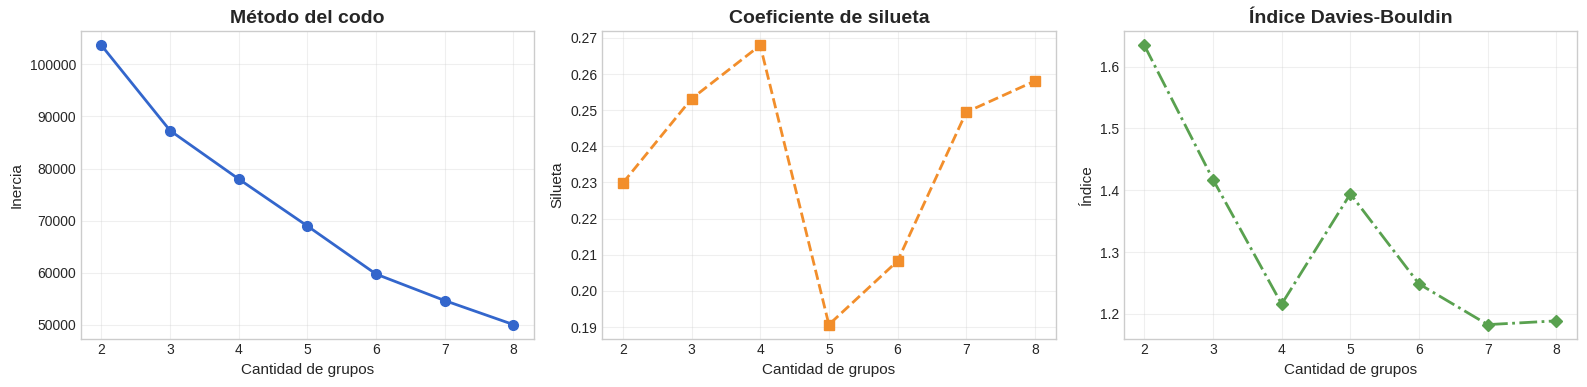

In [ ]:
## 12. SELECCIÓN DE K PARA K-MEANS

if 'X_train' not in globals():
    raise NameError("No existe 'X_train'. Ejecuta primero la sección 11.")

def muestra_metricas(Xmat,maximo=10000):
    if len(Xmat) <= maximo:
        return Xmat
    rng = np.random.default_rng(RANDOM_STATE)
    indices_muestra = rng.choice(len(Xmat),maximo,replace=False)
    return Xmat[indices_muestra]

X_eval_k = muestra_metricas(X_train)
resultados_k = []

for k in range(2,9):
    modelo = KMeans(n_clusters=k,n_init=10,max_iter=300,random_state=RANDOM_STATE)
    etiquetas = modelo.fit_predict(X_eval_k)
    resultados_k.append({
        'k':k,
        'inercia':modelo.inertia_,
        'silueta':silhouette_score(X_eval_k,etiquetas),
        'davies_bouldin':davies_bouldin_score(X_eval_k,etiquetas),
        'calinski_harabasz':calinski_harabasz_score(X_eval_k,etiquetas)
    })

df_k = pd.DataFrame(resultados_k)
K_SELECCIONADO = int(df_k.sort_values(['silueta','davies_bouldin'],ascending=[False,True]).iloc[0]['k'])

display(df_k.round(4))
print(f'Cantidad seleccionada de grupos: {K_SELECCIONADO}')

fig, axes = plt.subplots(1,3,figsize=(16,4))

axes[0].plot(df_k['k'],df_k['inercia'],color='#3366CC',linestyle='-',marker='o',linewidth=2,markersize=7)
axes[0].set_title('Método del codo',fontsize=14,fontweight='bold',fontfamily='sans-serif')
axes[0].set_xlabel('Cantidad de grupos'); axes[0].set_ylabel('Inercia')

axes[1].plot(df_k['k'],df_k['silueta'],color='#F28E2B',linestyle='--',marker='s',linewidth=2,markersize=7)
axes[1].set_title('Coeficiente de silueta',fontsize=14,fontweight='bold',fontfamily='sans-serif')
axes[1].set_xlabel('Cantidad de grupos'); axes[1].set_ylabel('Silueta')

axes[2].plot(df_k['k'],df_k['davies_bouldin'],color='#59A14F',linestyle='-.',marker='D',linewidth=2,markersize=6)
axes[2].set_title('Índice Davies-Bouldin',fontsize=14,fontweight='bold',fontfamily='sans-serif')
axes[2].set_xlabel('Cantidad de grupos'); axes[2].set_ylabel('Índice')

for ax in axes:
    ax.tick_params(labelsize=10)
    ax.grid(alpha=0.30)

plt.tight_layout(); plt.show()

### Interpretación

- **Método del codo:** muestra que al crear más grupos disminuyen las diferencias entre las cuentas de un mismo grupo. Sin embargo, agregar demasiados grupos aporta cada vez menos mejora.

- **Coeficiente de silueta:** indica qué tan bien separadas están las cuentas. Un valor más alto es mejor. El mejor resultado se obtuvo con **4 grupos**.

- **Índice Davies-Bouldin:** mide qué tan diferentes son los grupos entre sí. Un valor más bajo es mejor. Con 4 grupos se obtuvo un resultado adecuado, aunque con 7 fue ligeramente menor.

Considerando principalmente la mejor silueta y el buen resultado de Davies-Bouldin, se seleccionaron **4 grupos** para K-Means.

### Grupos

Los grupos representan conjuntos de cuentas con formas parecidas de realizar transferencias. La inercia mide las diferencias entre las cuentas dentro de cada grupo: mientras más baja, más parecidas son.

La silueta mide si los grupos están bien separados; un valor más alto es mejor. Davies-Bouldin también compara la separación, pero en este caso un valor más bajo es mejor. Los resultados indican que dividir las cuentas en **4 grupos** ofrece la opción más adecuada. El significado de cada grupo se conocerá después de entrenar y analizar K-Means.

```


```



## 13. Modelo 1: K-Means

In [ ]:
## 13. MODELO 1: K-MEANS

if 'X_train' not in globals() or 'X_test' not in globals():
    raise NameError("No existen X_train o X_test. Ejecuta primero la sección 11.")
if 'K_SELECCIONADO' not in globals():
    raise NameError("No existe K_SELECCIONADO. Ejecuta primero la sección 12.")

inicio = time.perf_counter()
modelo_kmeans = KMeans(n_clusters=K_SELECCIONADO,init='k-means++',n_init=20,max_iter=300,random_state=RANDOM_STATE)
modelo_kmeans.fit(X_train)

labels_k_train = modelo_kmeans.labels_
labels_k_test = modelo_kmeans.predict(X_test)
tiempo_kmeans = time.perf_counter()-inicio

perfil_train = df_perfil.iloc[idx_train].copy()
perfil_test = df_perfil.iloc[idx_test].copy()
perfil_train['cluster_kmeans'] = labels_k_train
perfil_test['cluster_kmeans'] = labels_k_test

distribucion_train = pd.Series(labels_k_train).value_counts().sort_index()
distribucion_test = pd.Series(labels_k_test).value_counts().sort_index()

resumen_kmeans = pd.DataFrame({
    'grupo':distribucion_train.index,
    'cuentas_entrenamiento':distribucion_train.values,
    'porcentaje_entrenamiento':distribucion_train.values/len(labels_k_train)*100,
    'cuentas_prueba':[distribucion_test.get(i,0) for i in distribucion_train.index],
    'porcentaje_prueba':[distribucion_test.get(i,0)/len(labels_k_test)*100 for i in distribucion_train.index]
})

centros_originales = scaler.inverse_transform(modelo_kmeans.cluster_centers_)
tabla_centros = pd.DataFrame(centros_originales,columns=FEATURES)
tabla_centros.insert(0,'grupo',range(K_SELECCIONADO))

print(f'Cantidad de grupos: {K_SELECCIONADO}')
print(f'Iteraciones realizadas: {modelo_kmeans.n_iter_}')
print(f'Tiempo de entrenamiento: {tiempo_kmeans:.2f} segundos')
display(resumen_kmeans.round(2))

print('Valores promedio de cada grupo:')
display(tabla_centros.round(2))

Cantidad de grupos: 4
Iteraciones realizadas: 10
Tiempo de entrenamiento: 2.29 segundos


,grupo,cuentas_entrenamiento,porcentaje_entrenamiento,cuentas_prueba,porcentaje_prueba
0,0,25930,42.43,6506,42.58
1,1,22941,37.54,5735,37.53
2,2,11189,18.31,2782,18.21
3,3,1058,1.73,257,1.68


Valores promedio de cada grupo:


,grupo,log_num_transferencias,log_monto_total,log_monto_promedio,log_monto_maximo,log_destinos_distintos,transferencias_por_dia,diversidad_destinos,coef_variacion_monto,pct_fin_semana,pct_nocturnas,pct_canal_movil,pct_montos_atipicos
0,0,1.03,3.45,2.95,3.16,0.88,1.07,0.84,0.33,17.88,4.94,99.95,0.00
1,1,2.33,6.09,3.92,5.20,1.67,1.36,0.55,1.36,20.53,4.86,99.84,8.11
2,2,1.31,7.29,6.38,6.86,0.85,1.14,0.62,0.67,14.25,5.50,99.76,75.54
3,3,1.23,5.75,4.96,5.33,0.91,1.14,0.72,0.49,16.08,5.70,3.36,37.96


### Interpretación

K-Means identificó cuatro comportamientos claros:

1. **Grupo 0 – Actividad baja (42,43 %):** pocas transferencias, montos bajos y uso de la aplicación móvil.
2. **Grupo 1 – Actividad frecuente (37,54 %):** más transferencias, varios destinos y pocos montos atípicos.
3. **Grupo 2 – Montos elevados (18,31 %):** pocas operaciones, pero el 75,54 % supera el monto habitual.
4. **Grupo 3 – Banca web (1,73 %):** grupo poco común que utiliza principalmente la banca web y presenta montos elevados.

Los grupos 2 y 3 son los más llamativos y deberían revisarse con mayor atención, aunque esto no significa que exista fraude.

## 14. Modelo 2: DBSCAN

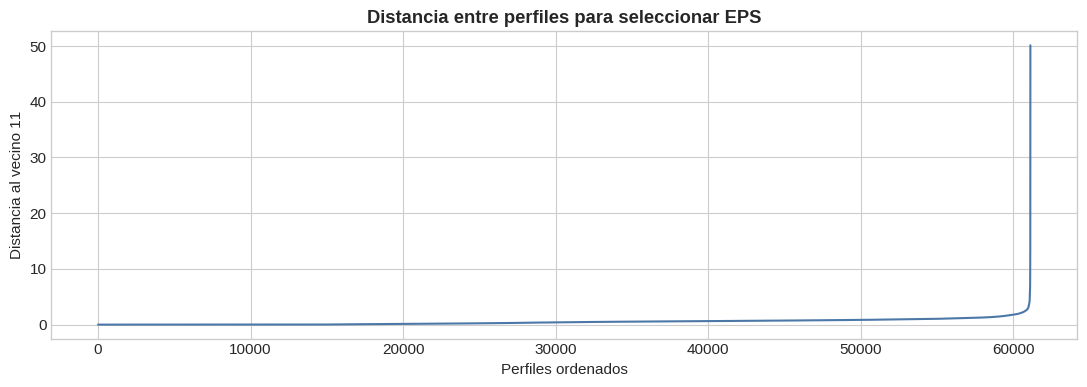

,percentil,eps,clusters,ruido_pct,silueta
0,0.70,0.68,86,21.48,0.02
1,0.75,0.75,73,16.81,-0.03
2,0.80,0.82,60,12.55,0.01
3,0.85,0.91,55,8.91,-0.08
4,0.90,1.04,43,5.58,-0.09
5,0.92,1.12,44,4.39,-0.10
6,0.95,1.28,26,2.75,0.08


EPS seleccionado: 1.2841
MIN_SAMPLES: 11
Tiempo de entrenamiento: 55.62 segundos
Grupos en entrenamiento: 26
Grupos en prueba: 25
Ruido en entrenamiento: 2.75%
Ruido en prueba: 2.81%


,grupo,entrenamiento,prueba,tipo
0,-1,1681,430,Ruido
1,0,57404,14333,Grupo
2,1,379,94,Grupo
3,2,39,11,Grupo
4,3,126,29,Grupo
5,4,360,101,Grupo
6,5,108,26,Grupo
7,6,451,124,Grupo
8,7,148,36,Grupo
9,8,140,28,Grupo


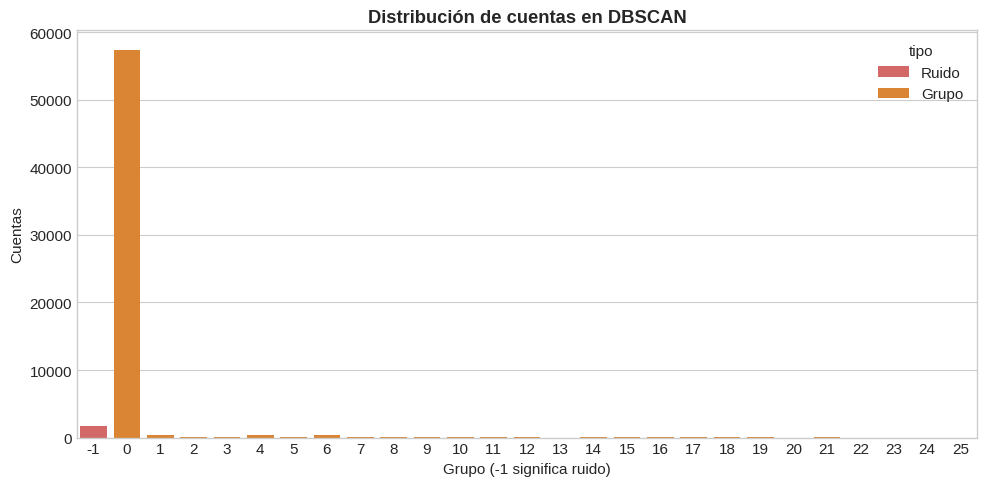

Resultados guardados en df_perfil['cluster_dbscan'].


In [ ]:
## 14. MODELO 2: DBSCAN

import time
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

if 'X_train' not in globals() or 'X_test' not in globals():
    raise NameError("No existen X_train o X_test. Ejecuta primero la sección 11.")
if 'idx_train' not in globals() or 'idx_test' not in globals():
    raise NameError("No existen idx_train o idx_test. Ejecuta primero la sección 11.")

indices_train = idx_train
indices_test = idx_test
MIN_SAMPLES = max(5,int(np.log(max(len(X_train),2))))

# Calcular las distancias entre perfiles
vecinos = NearestNeighbors(n_neighbors=MIN_SAMPLES,n_jobs=-1).fit(X_train)
distancias,_ = vecinos.kneighbors(X_train)
distancias_k = np.sort(distancias[:,-1])

# Mostrar curva de distancias
plt.figure(figsize=(11,4))
plt.plot(distancias_k,color='#4C78A8',linewidth=1.5)
plt.title('Distancia entre perfiles para seleccionar EPS',fontweight='bold')
plt.xlabel('Perfiles ordenados'); plt.ylabel(f'Distancia al vecino {MIN_SAMPLES}')
plt.tight_layout(); plt.show()

# Probar diferentes valores de EPS
resultados_eps = []
for percentil in [0.70,0.75,0.80,0.85,0.90,0.92,0.95]:
    eps_candidato = float(np.quantile(distancias_k,percentil))
    modelo_temporal = DBSCAN(eps=eps_candidato,min_samples=MIN_SAMPLES,n_jobs=-1)
    etiquetas = modelo_temporal.fit_predict(X_train)
    clusters = len(set(etiquetas)-{-1})
    ruido = (etiquetas == -1).mean()*100
    mascara = etiquetas != -1
    silueta = np.nan
    if clusters >= 2 and mascara.sum() > clusters:
        muestra = np.where(mascara)[0]
        if len(muestra) > 5000:
            rng = np.random.default_rng(RANDOM_STATE)
            muestra = rng.choice(muestra,5000,replace=False)
        silueta = silhouette_score(X_train[muestra],etiquetas[muestra])
    resultados_eps.append({'percentil':percentil,'eps':eps_candidato,'clusters':clusters,'ruido_pct':ruido,'silueta':silueta})

df_eps = pd.DataFrame(resultados_eps)
display(df_eps.round(4))

# Seleccionar EPS válido
candidatos = df_eps[(df_eps['clusters'] >= 2) & (df_eps['silueta'].notna()) & (df_eps['ruido_pct'] <= 50)].copy()
if candidatos.empty:
    mejor_eps = df_eps.iloc[(df_eps['percentil']-0.90).abs().argsort()[:1]].iloc[0]
else:
    mejor_eps = candidatos.sort_values(['silueta','ruido_pct'],ascending=[False,True]).iloc[0]

EPS = float(mejor_eps['eps'])
print(f'EPS seleccionado: {EPS:.4f}')
print(f'MIN_SAMPLES: {MIN_SAMPLES}')

# Entrenar DBSCAN
inicio = time.perf_counter()
modelo_dbscan = DBSCAN(eps=EPS,min_samples=MIN_SAMPLES,metric='euclidean',n_jobs=-1)
labels_db_train = modelo_dbscan.fit_predict(X_train)
tiempo_dbscan = time.perf_counter()-inicio

# Asignar perfiles de prueba al núcleo más cercano
def predecir_dbscan(modelo,X_nuevo):
    if not hasattr(modelo,'components_') or len(modelo.components_) == 0:
        return np.full(len(X_nuevo),-1,dtype=int)
    vecinos_core = NearestNeighbors(n_neighbors=1,n_jobs=-1).fit(modelo.components_)
    distancias,indices = vecinos_core.kneighbors(X_nuevo)
    etiquetas_core = modelo.labels_[modelo.core_sample_indices_]
    predicciones = etiquetas_core[indices[:,0]].astype(int)
    predicciones[distancias[:,0] > modelo.eps] = -1
    return predicciones

labels_db_test = predecir_dbscan(modelo_dbscan,X_test)

# Resultados
clusters_train = len(set(labels_db_train)-{-1})
clusters_test = len(set(labels_db_test)-{-1})
ruido_train = (labels_db_train == -1).mean()*100
ruido_test = (labels_db_test == -1).mean()*100

print(f'Tiempo de entrenamiento: {tiempo_dbscan:.2f} segundos')
print(f'Grupos en entrenamiento: {clusters_train}')
print(f'Grupos en prueba: {clusters_test}')
print(f'Ruido en entrenamiento: {ruido_train:.2f}%')
print(f'Ruido en prueba: {ruido_test:.2f}%')

distribucion_dbscan = pd.concat([
    pd.Series(labels_db_train).value_counts().sort_index().rename('entrenamiento'),
    pd.Series(labels_db_test).value_counts().sort_index().rename('prueba')
],axis=1).fillna(0).astype(int).reset_index().rename(columns={'index':'grupo'})

distribucion_dbscan['tipo'] = np.where(distribucion_dbscan['grupo'].eq(-1),'Ruido','Grupo')
display(distribucion_dbscan)

plt.figure(figsize=(10,5))
sns.barplot(data=distribucion_dbscan,x='grupo',y='entrenamiento',hue='tipo',palette={'Ruido':'#E45756','Grupo':'#F58518'})
plt.title('Distribución de cuentas en DBSCAN',fontweight='bold')
plt.xlabel('Grupo (-1 significa ruido)'); plt.ylabel('Cuentas')
plt.tight_layout(); plt.show()

df_perfil['cluster_dbscan'] = pd.Series(index=df_perfil.index,dtype='Int64')
df_perfil.loc[indices_train,'cluster_dbscan'] = labels_db_train
df_perfil.loc[indices_test,'cluster_dbscan'] = labels_db_test
df_perfil['cluster_dbscan'] = df_perfil['cluster_dbscan'].astype(int)

print("Resultados guardados en df_perfil['cluster_dbscan'].")

### Interpretación

DBSCAN colocó aproximadamente el 94 % de las cuentas en un solo grupo porque tienen comportamientos parecidos. También encontró varios grupos pequeños y marcó cerca del 2,8 % de las cuentas como poco comunes porque no encajaron en ningún grupo.

Los grupos pequeños no están claramente separados. Por esta razón, DBSCAN sirve principalmente para encontrar cuentas con comportamientos diferentes, mientras que K-Means es mejor para dividirlas en grupos fáciles de explicar.

## 15. Modelo 3: Isolation Forest

Isolation Forest busca cuentas cuyo comportamiento es diferente al de la mayoría. El modelo se configuró para señalar aproximadamente el 2 % de los perfiles como poco habituales. Esta clasificación no significa fraude, sino que indica cuentas que podrían revisarse con mayor atención.

MODELO ISOLATION FOREST ENTRENADO CORRECTAMENTE
Tiempo de entrenamiento: 2.29 segundos
Perfiles de entrenamiento: 61,118
Perfiles de prueba: 15,280
Perfiles atípicos en entrenamiento: 1,223 (2.00%)
Perfiles atípicos en prueba: 309 (2.02%)
Un perfil atípico representa un comportamiento poco habitual, no un fraude confirmado.


,conjunto,total_perfiles,perfiles_habituales,perfiles_atipicos,porcentaje_atipicos,puntaje_promedio,puntaje_maximo
0,Entrenamiento,61118,59895,1223,2.00,-0.13,0.14
1,Prueba,15280,14971,309,2.02,-0.13,0.14


Perfiles con mayor puntaje de atipicidad:


,CtaOrigen,num_transferencias,dias_con_actividad,monto_total,monto_promedio,monto_maximo,destinos_distintos,pct_nocturnas,pct_montos_atipicos,conjunto_modelado,puntaje_atipicidad,clasificacion_isolation
57087,cue_3886803587,105,31,"42,651.15",406.20,"5,000.00",44,12.38,12.38,Entrenamiento,0.14,Perfil atípico
21504,cue_2080926275,155,33,"82,352.03",531.30,"3,150.08",93,7.10,34.84,Prueba,0.14,Perfil atípico
23105,cue_2161978484,4,2,"42,188.06","10,547.02","37,000.00",1,100.00,50.00,Entrenamiento,0.13,Perfil atípico
7312,cue_1369323870,2,1,"19,000.00","9,500.00","18,000.00",1,100.00,100.00,Entrenamiento,0.13,Perfil atípico
28699,cue_2440193620,65,19,"17,305.12",266.23,"5,000.00",34,3.08,6.15,Entrenamiento,0.13,Perfil atípico
67723,cue_558244944,1,1,"9,400.00","9,400.00","9,400.00",1,100.00,100.00,Entrenamiento,0.13,Perfil atípico
63610,cue_4212821819,1,1,"67,390.95","67,390.95","67,390.95",1,100.00,100.00,Entrenamiento,0.13,Perfil atípico
20836,cue_2048601889,67,19,"9,058.33",135.20,"3,455.00",36,4.48,5.97,Entrenamiento,0.12,Perfil atípico
14259,cue_1714715449,66,23,"16,994.97",257.50,"5,000.00",40,3.03,7.58,Entrenamiento,0.12,Perfil atípico
56923,cue_3877737633,323,57,"12,155.30",37.63,"9,095.00",15,4.64,0.93,Entrenamiento,0.12,Perfil atípico


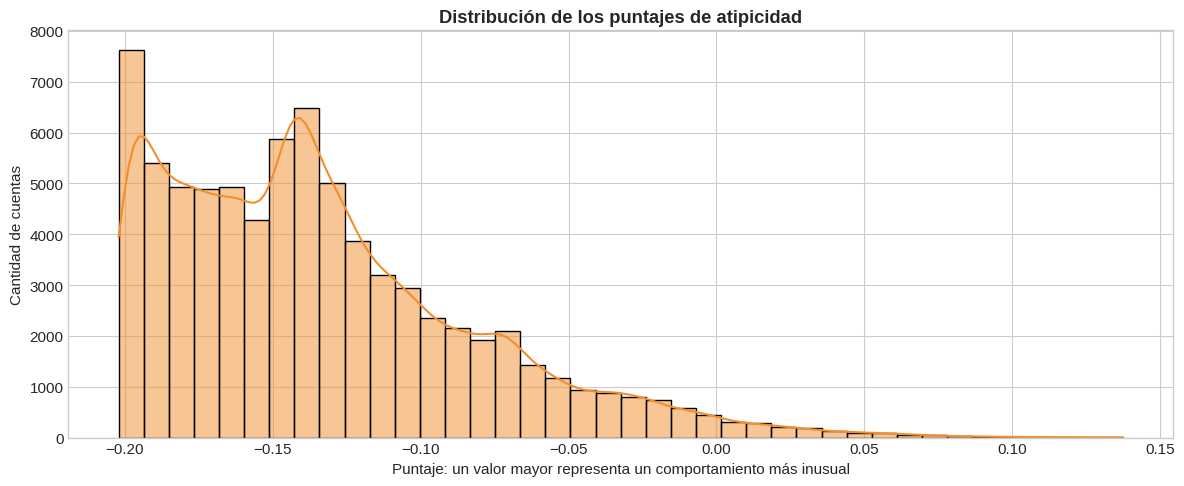

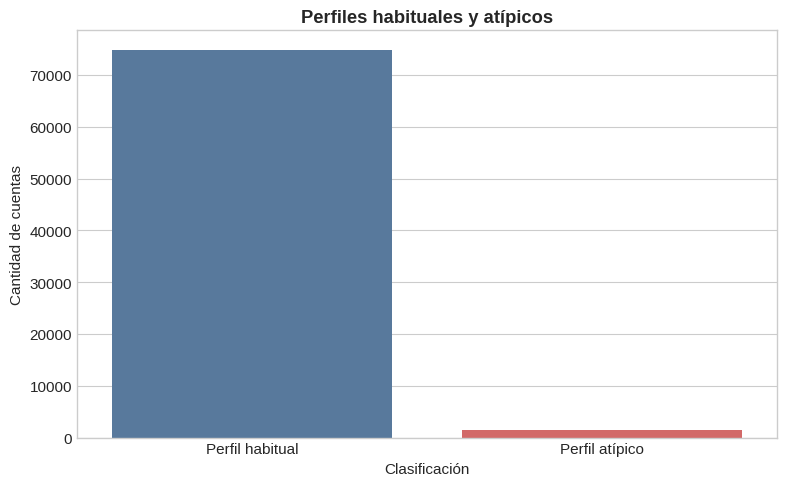

Resultados guardados en df_perfil: 'es_atipica_isolation', 'puntaje_atipicidad' y 'clasificacion_isolation'.


In [ ]:
## 15. MODELO 3: ISOLATION FOREST

import time
from sklearn.ensemble import IsolationForest

variables_requeridas = ['X_train','X_test','idx_train','idx_test','df_perfil']
faltantes = [v for v in variables_requeridas if v not in globals()]
if faltantes:
    raise NameError(f'Faltan variables necesarias: {faltantes}. Ejecuta primero las secciones 10 y 11.')

indices_train = idx_train
indices_test = idx_test
if len(X_train) < 10:
    raise ValueError('Se necesitan al menos 10 perfiles de entrenamiento.')

# Configurar y entrenar el modelo
CONTAMINACION = 0.02
parametros_isolation = {
    'n_estimators':300,
    'contamination':CONTAMINACION,
    'max_samples':'auto',
    'max_features':1.0,
    'bootstrap':False,
    'random_state':RANDOM_STATE,
    'n_jobs':-1
}

inicio = time.perf_counter()
modelo_isolation = IsolationForest(**parametros_isolation)
modelo_isolation.fit(X_train)
tiempo_iforest = time.perf_counter()-inicio

# Obtener resultados
labels_if_train = modelo_isolation.predict(X_train)
labels_if_test = modelo_isolation.predict(X_test)
scores_if_train = -modelo_isolation.decision_function(X_train)
scores_if_test = -modelo_isolation.decision_function(X_test)

atipicos_train = int((labels_if_train == -1).sum())
atipicos_test = int((labels_if_test == -1).sum())
pct_atipicos_train = atipicos_train/len(labels_if_train)*100
pct_atipicos_test = atipicos_test/len(labels_if_test)*100

print('MODELO ISOLATION FOREST ENTRENADO CORRECTAMENTE')
print(f'Tiempo de entrenamiento: {tiempo_iforest:.2f} segundos')
print(f'Perfiles de entrenamiento: {len(X_train):,}')
print(f'Perfiles de prueba: {len(X_test):,}')
print(f'Perfiles atípicos en entrenamiento: {atipicos_train:,} ({pct_atipicos_train:.2f}%)')
print(f'Perfiles atípicos en prueba: {atipicos_test:,} ({pct_atipicos_test:.2f}%)')
print('Un perfil atípico representa un comportamiento poco habitual, no un fraude confirmado.')

# Tabla resumen
resumen_isolation = pd.DataFrame({
    'conjunto':['Entrenamiento','Prueba'],
    'total_perfiles':[len(labels_if_train),len(labels_if_test)],
    'perfiles_habituales':[int((labels_if_train == 1).sum()),int((labels_if_test == 1).sum())],
    'perfiles_atipicos':[atipicos_train,atipicos_test],
    'porcentaje_atipicos':[pct_atipicos_train,pct_atipicos_test],
    'puntaje_promedio':[scores_if_train.mean(),scores_if_test.mean()],
    'puntaje_maximo':[scores_if_train.max(),scores_if_test.max()]
})
display(resumen_isolation.round(4))

# Guardar resultados en df_perfil
df_perfil['resultado_isolation'] = 0
df_perfil['es_atipica_isolation'] = 0
df_perfil['puntaje_atipicidad'] = 0.0
df_perfil['conjunto_modelado'] = ''

df_perfil.loc[indices_train,'resultado_isolation'] = labels_if_train
df_perfil.loc[indices_train,'es_atipica_isolation'] = (labels_if_train == -1).astype(int)
df_perfil.loc[indices_train,'puntaje_atipicidad'] = scores_if_train
df_perfil.loc[indices_train,'conjunto_modelado'] = 'Entrenamiento'

df_perfil.loc[indices_test,'resultado_isolation'] = labels_if_test
df_perfil.loc[indices_test,'es_atipica_isolation'] = (labels_if_test == -1).astype(int)
df_perfil.loc[indices_test,'puntaje_atipicidad'] = scores_if_test
df_perfil.loc[indices_test,'conjunto_modelado'] = 'Prueba'

df_perfil['resultado_isolation'] = df_perfil['resultado_isolation'].astype(int)
df_perfil['es_atipica_isolation'] = df_perfil['es_atipica_isolation'].astype(int)
df_perfil['clasificacion_isolation'] = np.where(df_perfil['es_atipica_isolation'].eq(1),'Perfil atípico','Perfil habitual')

# Mostrar las 20 cuentas más inusuales
columnas_atipicas = ['CtaOrigen','num_transferencias','dias_con_actividad','monto_total','monto_promedio','monto_maximo','destinos_distintos','pct_nocturnas','pct_montos_atipicos','conjunto_modelado','puntaje_atipicidad','clasificacion_isolation']
columnas_atipicas = [c for c in columnas_atipicas if c in df_perfil.columns]

print('Perfiles con mayor puntaje de atipicidad:')
display(df_perfil[columnas_atipicas].sort_values('puntaje_atipicidad',ascending=False).head(20))

# Gráfico de puntajes
plt.figure(figsize=(12,5))
sns.histplot(df_perfil['puntaje_atipicidad'],bins=40,kde=True,color='#F28E2B')
plt.title('Distribución de los puntajes de atipicidad',fontweight='bold')
plt.xlabel('Puntaje: un valor mayor representa un comportamiento más inusual')
plt.ylabel('Cantidad de cuentas')
plt.tight_layout(); plt.show()

# Gráfico de clasificación
conteo_clasificacion = df_perfil['clasificacion_isolation'].value_counts().rename_axis('clasificacion').reset_index(name='cantidad')
plt.figure(figsize=(8,5))
sns.barplot(data=conteo_clasificacion,x='clasificacion',y='cantidad',hue='clasificacion',palette={'Perfil habitual':'#4C78A8','Perfil atípico':'#E45756'},legend=False)
plt.title('Perfiles habituales y atípicos',fontweight='bold')
plt.xlabel('Clasificación'); plt.ylabel('Cantidad de cuentas')
plt.tight_layout(); plt.show()

print("Resultados guardados en df_perfil: 'es_atipica_isolation', 'puntaje_atipicidad' y 'clasificacion_isolation'.")

### Interpretación

Isolation Forest identificó 1.532 cuentas con comportamientos poco habituales, aproximadamente el 2 % del total. Los resultados fueron casi iguales en entrenamiento y prueba, lo que muestra estabilidad.

Las cuentas destacadas presentan características como montos muy altos o muy bajos, muchas transferencias, varios destinos u operaciones nocturnas. Estas cuentas deberían revisarse con mayor atención, pero su clasificación como atípicas no significa que exista fraude.

## 16. Evaluación sobre el conjunto de prueba

En esta sección se comparan los resultados de los tres modelos utilizando las cuentas reservadas para prueba. K-Means y DBSCAN se evalúan según la separación de sus grupos, mientras que Isolation Forest se analiza mediante la cantidad y el puntaje de los perfiles atípicos encontrados.

COMPARACIÓN DE MODELOS EN EL CONJUNTO DE PRUEBA


,Tecnica,Proposito,Grupos,Perfiles_evaluados,Silueta,Davies_Bouldin,Calinski_Harabasz,Porcentaje_especial,Significado,Tiempo_segundos
0,K-Means,Segmentar cuentas,4.00,15280,0.28,1.18,"1,316.87",0.00,No aplica,2.29
1,DBSCAN,Encontrar grupos y ruido,25.00,14850,0.07,0.69,42.30,2.81,Ruido,55.62
2,Isolation Forest,Encontrar perfiles atípicos,NaN,15280,NaN,NaN,NaN,2.02,Perfiles atípicos,2.29


RESULTADOS PRINCIPALES
K-Means: silueta 0.2756 y Davies-Bouldin 1.1795.
DBSCAN: silueta 0.0654, Davies-Bouldin 0.6914 y ruido 2.81%.
Isolation Forest: 309 perfiles atípicos (2.02%).
En Silueta un valor mayor es mejor; en Davies-Bouldin un valor menor es mejor.


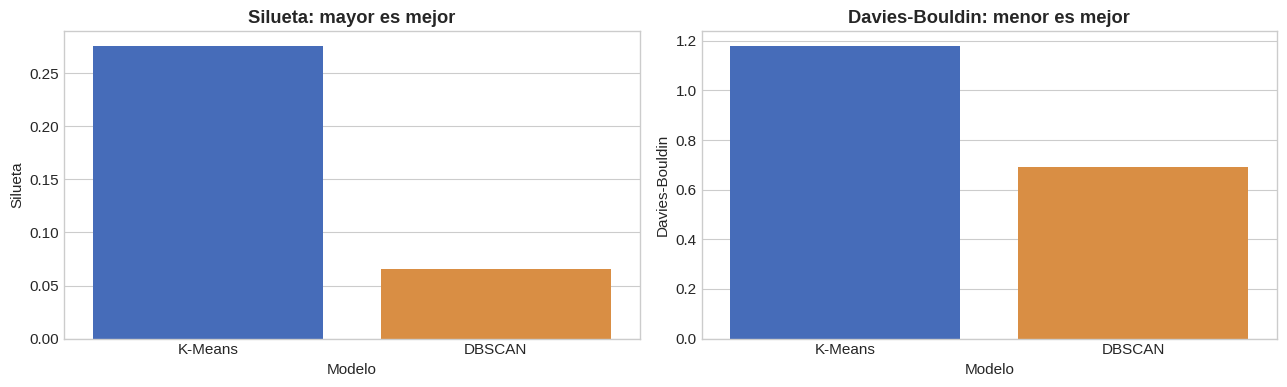

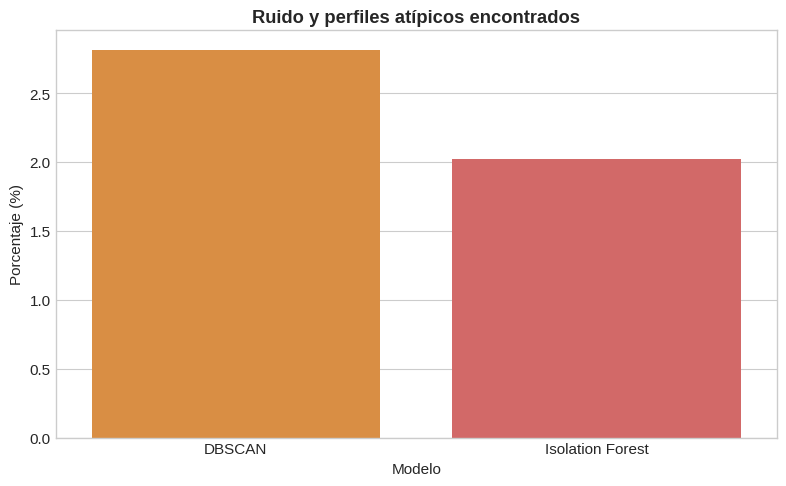

Evaluación del conjunto de prueba completada correctamente.


In [ ]:
## 16. EVALUACIÓN SOBRE EL CONJUNTO DE PRUEBA

variables_requeridas = ['X_test','labels_k_test','labels_db_test','labels_if_test','scores_if_test','tiempo_kmeans','tiempo_dbscan','tiempo_iforest']
faltantes = [v for v in variables_requeridas if v not in globals()]
if faltantes:
    raise NameError(f'Faltan variables: {faltantes}. Ejecuta primero las secciones 13, 14 y 15.')

if len(labels_k_test) != len(X_test) or len(labels_db_test) != len(X_test) or len(labels_if_test) != len(X_test):
    raise ValueError('Las etiquetas de los modelos no coinciden con la cantidad de perfiles de prueba.')

# Función para calcular métricas
def metricas_clustering(Xmat,etiquetas,ignorar_ruido=False,maximo=5000):
    X_use = np.asarray(Xmat)
    y_use = np.asarray(etiquetas)
    if ignorar_ruido:
        mascara = y_use != -1
        X_use,y_use = X_use[mascara],y_use[mascara]

    numero_clusters = len(np.unique(y_use))
    total = len(y_use)
    if total < 3 or numero_clusters < 2 or numero_clusters >= total:
        return {'silueta':np.nan,'davies_bouldin':np.nan,'calinski_harabasz':np.nan,'clusters':numero_clusters,'evaluados':total}

    if total > maximo:
        rng = np.random.default_rng(RANDOM_STATE)
        indices = rng.choice(total,maximo,replace=False)
        X_muestra,y_muestra = X_use[indices],y_use[indices]
    else:
        X_muestra,y_muestra = X_use,y_use

    if len(np.unique(y_muestra)) < 2:
        return {'silueta':np.nan,'davies_bouldin':np.nan,'calinski_harabasz':np.nan,'clusters':numero_clusters,'evaluados':total}

    return {
        'silueta':silhouette_score(X_muestra,y_muestra),
        'davies_bouldin':davies_bouldin_score(X_muestra,y_muestra),
        'calinski_harabasz':calinski_harabasz_score(X_muestra,y_muestra),
        'clusters':numero_clusters,
        'evaluados':total
    }

# Evaluar K-Means y DBSCAN
metricas_kmeans = metricas_clustering(X_test,labels_k_test)
metricas_dbscan = metricas_clustering(X_test,labels_db_test,ignorar_ruido=True)

# Resultados especiales
porcentaje_ruido_test = (np.asarray(labels_db_test) == -1).mean()*100
cantidad_atipicos_test = int((np.asarray(labels_if_test) == -1).sum())
porcentaje_atipicos_test = cantidad_atipicos_test/len(labels_if_test)*100
score_promedio_if = float(np.mean(scores_if_test))
score_maximo_if = float(np.max(scores_if_test))

# Tabla comparativa
comparacion = pd.DataFrame([
    {
        'Tecnica':'K-Means',
        'Proposito':'Segmentar cuentas',
        'Grupos':metricas_kmeans['clusters'],
        'Perfiles_evaluados':metricas_kmeans['evaluados'],
        'Silueta':metricas_kmeans['silueta'],
        'Davies_Bouldin':metricas_kmeans['davies_bouldin'],
        'Calinski_Harabasz':metricas_kmeans['calinski_harabasz'],
        'Porcentaje_especial':0,
        'Significado':'No aplica',
        'Tiempo_segundos':tiempo_kmeans
    },
    {
        'Tecnica':'DBSCAN',
        'Proposito':'Encontrar grupos y ruido',
        'Grupos':metricas_dbscan['clusters'],
        'Perfiles_evaluados':metricas_dbscan['evaluados'],
        'Silueta':metricas_dbscan['silueta'],
        'Davies_Bouldin':metricas_dbscan['davies_bouldin'],
        'Calinski_Harabasz':metricas_dbscan['calinski_harabasz'],
        'Porcentaje_especial':porcentaje_ruido_test,
        'Significado':'Ruido',
        'Tiempo_segundos':tiempo_dbscan
    },
    {
        'Tecnica':'Isolation Forest',
        'Proposito':'Encontrar perfiles atípicos',
        'Grupos':np.nan,
        'Perfiles_evaluados':len(labels_if_test),
        'Silueta':np.nan,
        'Davies_Bouldin':np.nan,
        'Calinski_Harabasz':np.nan,
        'Porcentaje_especial':porcentaje_atipicos_test,
        'Significado':'Perfiles atípicos',
        'Tiempo_segundos':tiempo_iforest
    }
])

print('COMPARACIÓN DE MODELOS EN EL CONJUNTO DE PRUEBA')
display(comparacion.round(4))

print('RESULTADOS PRINCIPALES')
print(f'K-Means: silueta {metricas_kmeans["silueta"]:.4f} y Davies-Bouldin {metricas_kmeans["davies_bouldin"]:.4f}.')
print(f'DBSCAN: silueta {metricas_dbscan["silueta"]:.4f}, Davies-Bouldin {metricas_dbscan["davies_bouldin"]:.4f} y ruido {porcentaje_ruido_test:.2f}%.')
print(f'Isolation Forest: {cantidad_atipicos_test:,} perfiles atípicos ({porcentaje_atipicos_test:.2f}%).')
print('En Silueta un valor mayor es mejor; en Davies-Bouldin un valor menor es mejor.')

# Comparación de métricas
fig,axes = plt.subplots(1,2,figsize=(13,4))
datos_cluster = comparacion[comparacion['Tecnica'].isin(['K-Means','DBSCAN'])]

sns.barplot(data=datos_cluster,x='Tecnica',y='Silueta',hue='Tecnica',palette={'K-Means':'#3366CC','DBSCAN':'#F28E2B'},legend=False,ax=axes[0])
axes[0].set_title('Silueta: mayor es mejor',fontweight='bold'); axes[0].set_xlabel('Modelo'); axes[0].set_ylabel('Silueta')

sns.barplot(data=datos_cluster,x='Tecnica',y='Davies_Bouldin',hue='Tecnica',palette={'K-Means':'#3366CC','DBSCAN':'#F28E2B'},legend=False,ax=axes[1])
axes[1].set_title('Davies-Bouldin: menor es mejor',fontweight='bold'); axes[1].set_xlabel('Modelo'); axes[1].set_ylabel('Davies-Bouldin')
plt.tight_layout(); plt.show()

# Comparación de ruido y perfiles atípicos
porcentajes = comparacion[comparacion['Significado'] != 'No aplica']
plt.figure(figsize=(8,5))
sns.barplot(data=porcentajes,x='Tecnica',y='Porcentaje_especial',hue='Tecnica',palette={'DBSCAN':'#F28E2B','Isolation Forest':'#E45756'},legend=False)
plt.title('Ruido y perfiles atípicos encontrados',fontweight='bold')
plt.xlabel('Modelo'); plt.ylabel('Porcentaje (%)')
plt.tight_layout(); plt.show()

print('Evaluación del conjunto de prueba completada correctamente.')

### Interpretación

**K-Means** fue el mejor para dividir las cuentas en grupos claros. **DBSCAN** encontró muchos grupos pequeños y señaló el 2,81 % como cuentas poco comunes. **Isolation Forest** identificó el 2,02 % como perfiles atípicos.

Por lo tanto, K-Means es más útil para segmentar las cuentas, mientras que DBSCAN e Isolation Forest ayudan a encontrar comportamientos que requieren revisión.

## 17. Validación cruzada de cinco particiones

La validación cruzada divide los perfiles en cinco partes. En cada prueba se utilizan cuatro partes para entrenar los modelos y una parte diferente para comprobar sus resultados. Este proceso se repite cinco veces para verificar que los modelos funcionen de manera estable con distintas cuentas.




Iniciando validación cruzada de cinco particiones...
Procesando partición 1 de 5...
Procesando partición 2 de 5...
Procesando partición 3 de 5...
Procesando partición 4 de 5...
Procesando partición 5 de 5...
RESULTADOS DE LAS CINCO PARTICIONES


,Particion,Tecnica,Silueta,Davies_Bouldin,Calinski_Harabasz,Grupos,Pct_especial,Significado,Tiempo_segundos
0,1,K-Means,0.28,1.17,"1,383.39",4.00,0.00,No aplica,1.65
1,1,DBSCAN,0.09,0.76,61.85,25.00,2.81,Ruido,57.62
2,1,Isolation Forest,NaN,NaN,NaN,NaN,2.02,Perfiles atípicos,1.69
3,2,K-Means,0.27,1.22,979.42,4.00,0.00,No aplica,1.16
4,2,DBSCAN,0.04,0.66,51.20,19.00,2.79,Ruido,58.38
5,2,Isolation Forest,NaN,NaN,NaN,NaN,1.98,Perfiles atípicos,1.66
6,3,K-Means,0.27,1.22,"1,289.31",4.00,0.00,No aplica,1.13
7,3,DBSCAN,0.04,0.73,42.54,25.00,2.85,Ruido,54.78
8,3,Isolation Forest,NaN,NaN,NaN,NaN,1.85,Perfiles atípicos,1.65
9,4,K-Means,0.27,1.20,"1,306.47",4.00,0.00,No aplica,0.93


RESUMEN DE VALIDACIÓN CRUZADA


,Tecnica,Silueta_media,Silueta_desviacion,Davies_Bouldin_medio,Calinski_Harabasz_medio,Grupos_promedio,Porcentaje_especial_medio,Porcentaje_especial_desviacion,Tiempo_medio_segundos
0,DBSCAN,0.08,0.04,0.69,57.99,22.20,2.88,0.09,57.16
1,Isolation Forest,NaN,NaN,NaN,NaN,NaN,2.00,0.10,1.71
2,K-Means,0.27,0.00,1.22,"1,231.21",4.00,0.00,0.00,1.22


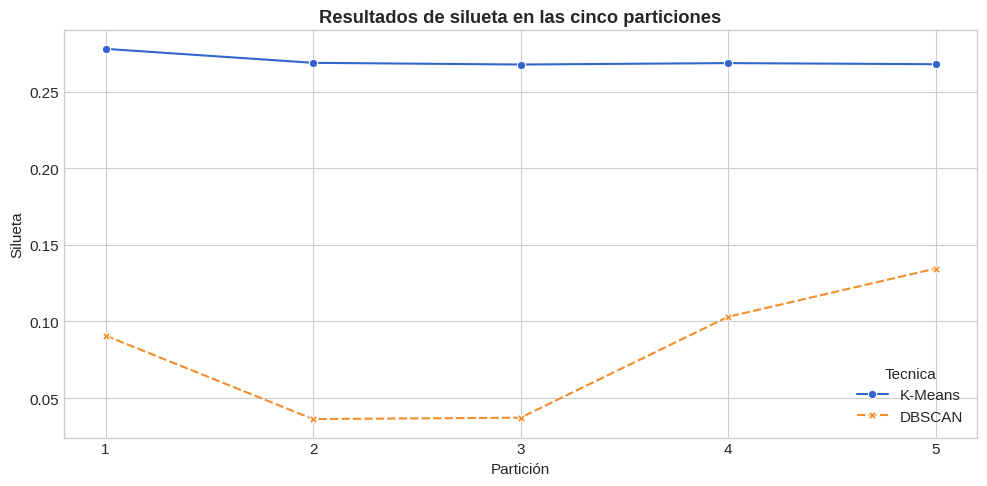

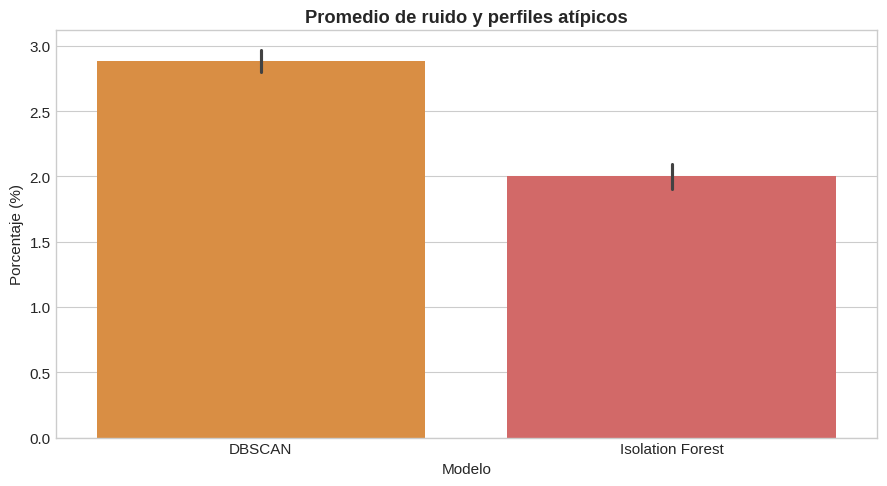

Validación cruzada de cinco particiones completada correctamente.


In [ ]:
## 17. VALIDACIÓN CRUZADA DE CINCO PARTICIONES

from sklearn.model_selection import KFold

variables_requeridas = ['X','K_SELECCIONADO','CONTAMINACION']
faltantes = [v for v in variables_requeridas if v not in globals()]
if faltantes:
    raise NameError(f'Faltan variables: {faltantes}. Ejecuta primero las secciones anteriores.')

X_cv = X.copy().replace([np.inf,-np.inf],np.nan).fillna(X.median(numeric_only=True)).fillna(0)
NUMERO_FOLDS = 5
PERCENTIL_EPS = float(mejor_eps['percentil']) if 'mejor_eps' in globals() else 0.95
kfold = KFold(n_splits=NUMERO_FOLDS,shuffle=True,random_state=RANDOM_STATE)
resultados_cv = []

def evaluar_clusters_cv(Xmat,etiquetas,ignorar_ruido=False,maximo=5000):
    X_use,y_use = np.asarray(Xmat),np.asarray(etiquetas)
    if ignorar_ruido:
        mascara = y_use != -1
        X_use,y_use = X_use[mascara],y_use[mascara]
    numero_clusters = len(np.unique(y_use))
    if len(y_use) < 3 or numero_clusters < 2 or numero_clusters >= len(y_use):
        return np.nan,np.nan,np.nan,numero_clusters
    if len(y_use) > maximo:
        rng = np.random.default_rng(RANDOM_STATE)
        indices = rng.choice(len(y_use),maximo,replace=False)
        X_use,y_use = X_use[indices],y_use[indices]
    if len(np.unique(y_use)) < 2:
        return np.nan,np.nan,np.nan,numero_clusters
    return silhouette_score(X_use,y_use),davies_bouldin_score(X_use,y_use),calinski_harabasz_score(X_use,y_use),numero_clusters

print('Iniciando validación cruzada de cinco particiones...')

for fold,(idx_ent,idx_val) in enumerate(kfold.split(X_cv),start=1):
    print(f'Procesando partición {fold} de {NUMERO_FOLDS}...')
    scaler_cv = StandardScaler()
    X_ent = scaler_cv.fit_transform(X_cv.iloc[idx_ent])
    X_val = scaler_cv.transform(X_cv.iloc[idx_val])

    # K-Means
    inicio = time.perf_counter()
    km_cv = KMeans(n_clusters=K_SELECCIONADO,init='k-means++',n_init=10,max_iter=300,random_state=RANDOM_STATE)
    km_cv.fit(X_ent)
    etiquetas_km = km_cv.predict(X_val)
    tiempo_km = time.perf_counter()-inicio
    sil_km,dav_km,cal_km,clusters_km = evaluar_clusters_cv(X_val,etiquetas_km)
    resultados_cv.append({'Particion':fold,'Tecnica':'K-Means','Silueta':sil_km,'Davies_Bouldin':dav_km,'Calinski_Harabasz':cal_km,'Grupos':clusters_km,'Pct_especial':0,'Significado':'No aplica','Tiempo_segundos':tiempo_km})

    # DBSCAN
    min_cv = max(5,int(np.log(max(len(X_ent),2))))
    vecinos_cv = NearestNeighbors(n_neighbors=min_cv,n_jobs=-1).fit(X_ent)
    distancias_cv,_ = vecinos_cv.kneighbors(X_ent)
    eps_cv = float(np.quantile(distancias_cv[:,-1],PERCENTIL_EPS))
    inicio = time.perf_counter()
    db_cv = DBSCAN(eps=eps_cv,min_samples=min_cv,n_jobs=-1).fit(X_ent)
    etiquetas_db = predecir_dbscan(db_cv,X_val)
    tiempo_db = time.perf_counter()-inicio
    sil_db,dav_db,cal_db,clusters_db = evaluar_clusters_cv(X_val,etiquetas_db,ignorar_ruido=True)
    pct_ruido = (etiquetas_db == -1).mean()*100
    resultados_cv.append({'Particion':fold,'Tecnica':'DBSCAN','Silueta':sil_db,'Davies_Bouldin':dav_db,'Calinski_Harabasz':cal_db,'Grupos':clusters_db,'Pct_especial':pct_ruido,'Significado':'Ruido','Tiempo_segundos':tiempo_db})

    # Isolation Forest
    inicio = time.perf_counter()
    iso_cv = IsolationForest(n_estimators=200,contamination=CONTAMINACION,max_samples='auto',random_state=RANDOM_STATE,n_jobs=-1)
    iso_cv.fit(X_ent)
    etiquetas_if = iso_cv.predict(X_val)
    tiempo_if = time.perf_counter()-inicio
    pct_atipicos = (etiquetas_if == -1).mean()*100
    resultados_cv.append({'Particion':fold,'Tecnica':'Isolation Forest','Silueta':np.nan,'Davies_Bouldin':np.nan,'Calinski_Harabasz':np.nan,'Grupos':np.nan,'Pct_especial':pct_atipicos,'Significado':'Perfiles atípicos','Tiempo_segundos':tiempo_if})

df_cv = pd.DataFrame(resultados_cv)

resumen_cv = df_cv.groupby('Tecnica',as_index=False).agg(
    Silueta_media=('Silueta','mean'),
    Silueta_desviacion=('Silueta','std'),
    Davies_Bouldin_medio=('Davies_Bouldin','mean'),
    Calinski_Harabasz_medio=('Calinski_Harabasz','mean'),
    Grupos_promedio=('Grupos','mean'),
    Porcentaje_especial_medio=('Pct_especial','mean'),
    Porcentaje_especial_desviacion=('Pct_especial','std'),
    Tiempo_medio_segundos=('Tiempo_segundos','mean')
)

print('RESULTADOS DE LAS CINCO PARTICIONES')
display(df_cv.round(4))
print('RESUMEN DE VALIDACIÓN CRUZADA')
display(resumen_cv.round(4))

# Estabilidad de la silueta
datos_silueta = df_cv.dropna(subset=['Silueta'])
plt.figure(figsize=(10,5))
sns.lineplot(data=datos_silueta,x='Particion',y='Silueta',hue='Tecnica',style='Tecnica',markers=True,dashes=True,palette={'K-Means':'#3366CC','DBSCAN':'#F28E2B'})
plt.title('Resultados de silueta en las cinco particiones',fontweight='bold')
plt.xlabel('Partición'); plt.ylabel('Silueta')
plt.xticks(range(1,6)); plt.tight_layout(); plt.show()

# Ruido y perfiles atípicos
datos_especiales = df_cv[df_cv['Significado'] != 'No aplica']
plt.figure(figsize=(9,5))
sns.barplot(data=datos_especiales,x='Tecnica',y='Pct_especial',errorbar='sd',hue='Tecnica',palette={'DBSCAN':'#F28E2B','Isolation Forest':'#E45756'},legend=False)
plt.title('Promedio de ruido y perfiles atípicos',fontweight='bold')
plt.xlabel('Modelo'); plt.ylabel('Porcentaje (%)')
plt.tight_layout(); plt.show()

print('Validación cruzada de cinco particiones completada correctamente.')

### Interpretación

K-Means obtuvo resultados muy parecidos en las cinco pruebas, por lo que es el modelo más estable para agrupar las cuentas. DBSCAN presentó resultados más bajos y variables, confirmando que sus grupos son menos claros.

Isolation Forest mantuvo cerca del 2 % de perfiles atípicos y DBSCAN alrededor del 2,9 % de cuentas no agrupadas. Por lo tanto, K-Means es más útil para segmentar, mientras que los otros dos modelos ayudan a localizar comportamientos poco comunes.

## 18. Entrenamiento final, asignación e interpretación

Después de comprobar la estabilidad de los modelos, se vuelven a entrenar utilizando todos los perfiles disponibles. Esto permite asignar un grupo y un puntaje de atipicidad definitivo a cada cuenta.

### Representación gráfica del modelo

Cada punto de la gráfica representa una cuenta de origen y su color indica el grupo asignado por K-Means. Debido a que el modelo utiliza 12 características, se aplicó PCA para resumirlas en dos componentes y poder mostrarlas en una gráfica. La posición de los puntos sirve como representación visual; el modelo real continúa utilizando las 12 características originales.

,cluster_kmeans,cuentas,transferencias_promedio,monto_promedio,monto_total_promedio,destinos_promedio,pct_nocturnas,pct_movil,pct_montos_altos,pct_perfiles_atipicos,porcentaje_cuentas
0,0,28644,12.06,82.23,995.89,5.44,4.89,99.84,7.98,1.83,37.49
1,1,32404,2.00,35.38,62.28,1.53,4.96,99.95,0.00,0.33,42.41
2,2,14035,3.39,"1,832.66","4,913.26",1.45,5.41,99.74,75.36,3.89,18.37
3,3,1315,3.62,"1,089.63","2,356.73",1.80,5.65,3.42,37.48,26.77,1.72


K-Means: 4 grupos finales
DBSCAN: 26 grupos y 2.76% de ruido
Isolation Forest: 1,528 perfiles atípicos (2.00%)
EPS final de DBSCAN: 1.2415


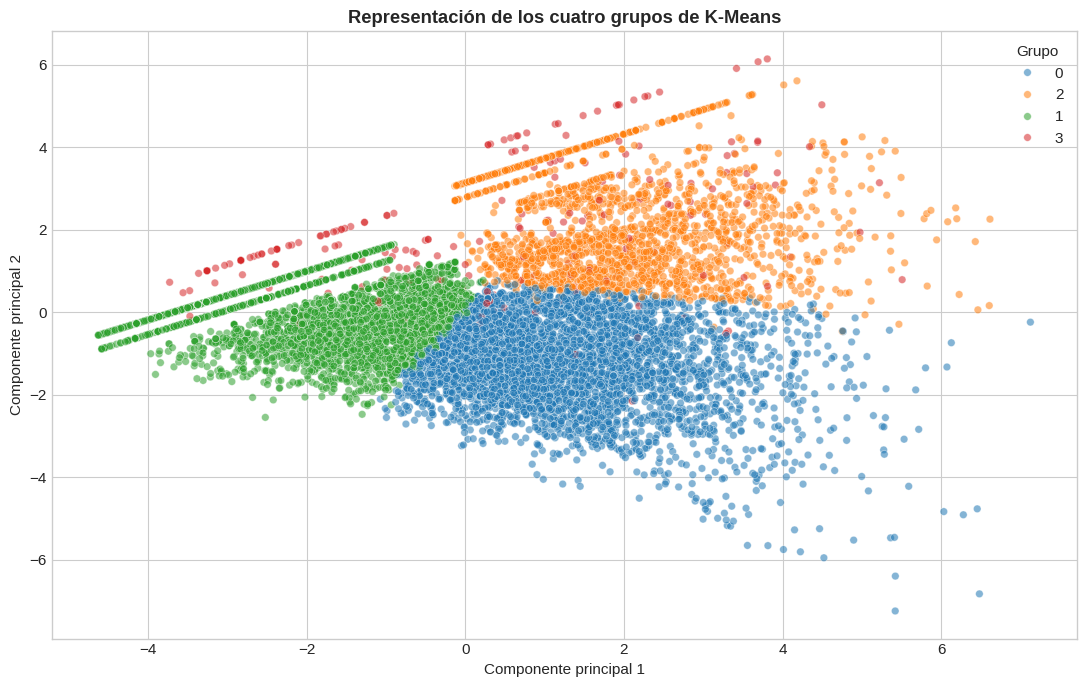

Cuentas con comportamiento más inusual:


,CtaOrigen,num_transferencias,monto_total,monto_promedio,monto_maximo,destinos_distintos,pct_nocturnas,pct_montos_atipicos,cluster_kmeans,cluster_dbscan,puntaje_atipicidad
21504,cue_2080926275,155,"82,352.03",531.30,"3,150.08",93,7.10,34.84,3,-1,0.15
7312,cue_1369323870,2,"19,000.00","9,500.00","18,000.00",1,100.00,100.00,3,-1,0.14
57087,cue_3886803587,105,"42,651.15",406.20,"5,000.00",44,12.38,12.38,3,-1,0.14
63610,cue_4212821819,1,"67,390.95","67,390.95","67,390.95",1,100.00,100.00,3,-1,0.13
67723,cue_558244944,1,"9,400.00","9,400.00","9,400.00",1,100.00,100.00,3,-1,0.13
23105,cue_2161978484,4,"42,188.06","10,547.02","37,000.00",1,100.00,50.00,3,-1,0.13
6628,cue_1334344195,3,0.03,0.01,0.01,1,100.00,0.00,1,-1,0.11
24874,cue_2248421290,5,"34,652.74","6,930.55","8,664.00",1,100.00,80.00,2,-1,0.11
19685,cue_199003756,104,"38,610.65",371.26,"5,000.00",93,1.92,12.50,0,-1,0.11
28699,cue_2440193620,65,"17,305.12",266.23,"5,000.00",34,3.08,6.15,0,-1,0.11


Entrenamiento final completado correctamente.


In [ ]:
## 18. ENTRENAMIENTO FINAL, ASIGNACIÓN E INTERPRETACIÓN

from sklearn.decomposition import PCA

variables_requeridas = ['X','df_perfil','FEATURES','K_SELECCIONADO','CONTAMINACION']
faltantes = [v for v in variables_requeridas if v not in globals()]
if faltantes:
    raise NameError(f'Faltan variables: {faltantes}. Ejecuta primero las secciones anteriores.')

# Escalar todos los perfiles
scaler_final = StandardScaler()
X_final = scaler_final.fit_transform(X[FEATURES])

# K-Means final
modelo_kmeans_final = KMeans(n_clusters=K_SELECCIONADO,init='k-means++',n_init=20,max_iter=300,random_state=RANDOM_STATE)
modelo_kmeans_final.fit(X_final)

# DBSCAN final
MIN_SAMPLES_FINAL = max(5,int(np.log(max(len(X_final),2))))
PERCENTIL_EPS_FINAL = float(mejor_eps['percentil']) if 'mejor_eps' in globals() else 0.95
vecinos_final = NearestNeighbors(n_neighbors=MIN_SAMPLES_FINAL,n_jobs=-1).fit(X_final)
distancias_final,_ = vecinos_final.kneighbors(X_final)
EPS_FINAL = float(np.quantile(distancias_final[:,-1],PERCENTIL_EPS_FINAL))
modelo_dbscan_final = DBSCAN(eps=EPS_FINAL,min_samples=MIN_SAMPLES_FINAL,n_jobs=-1)
labels_dbscan_final = modelo_dbscan_final.fit_predict(X_final)

# Isolation Forest final
modelo_isolation_final = IsolationForest(n_estimators=300,contamination=CONTAMINACION,max_samples='auto',random_state=RANDOM_STATE,n_jobs=-1)
modelo_isolation_final.fit(X_final)

# Asignar resultados definitivos
df_perfil['cluster_kmeans'] = modelo_kmeans_final.labels_
df_perfil['cluster_dbscan'] = labels_dbscan_final
df_perfil['es_atipica_isolation'] = (modelo_isolation_final.predict(X_final) == -1).astype(int)
df_perfil['puntaje_atipicidad'] = -modelo_isolation_final.decision_function(X_final)
df_perfil['clasificacion_isolation'] = np.where(df_perfil['es_atipica_isolation'].eq(1),'Perfil atípico','Perfil habitual')

# Resumen de los grupos finales de K-Means
resumen_clusters = df_perfil.groupby('cluster_kmeans').agg(
    cuentas=('CtaOrigen','size'),
    transferencias_promedio=('num_transferencias','mean'),
    monto_promedio=('monto_promedio','mean'),
    monto_total_promedio=('monto_total','mean'),
    destinos_promedio=('destinos_distintos','mean'),
    pct_nocturnas=('pct_nocturnas','mean'),
    pct_movil=('pct_canal_movil','mean'),
    pct_montos_altos=('pct_montos_atipicos','mean'),
    pct_perfiles_atipicos=('es_atipica_isolation','mean')
).reset_index()

resumen_clusters['porcentaje_cuentas'] = resumen_clusters['cuentas']/len(df_perfil)*100
resumen_clusters['pct_perfiles_atipicos'] *= 100
display(resumen_clusters.round(2))

print(f'K-Means: {K_SELECCIONADO} grupos finales')
print(f'DBSCAN: {len(set(labels_dbscan_final)-{-1})} grupos y {(labels_dbscan_final == -1).mean()*100:.2f}% de ruido')
print(f'Isolation Forest: {df_perfil["es_atipica_isolation"].sum():,} perfiles atípicos ({df_perfil["es_atipica_isolation"].mean()*100:.2f}%)')
print(f'EPS final de DBSCAN: {EPS_FINAL:.4f}')

# Visualización PCA
pca = PCA(n_components=2)
coordenadas = pca.fit_transform(X_final)
grafico = pd.DataFrame({'Componente 1':coordenadas[:,0],'Componente 2':coordenadas[:,1],'Grupo':df_perfil['cluster_kmeans'].astype(str)})
if len(grafico) > 12000:
    grafico = grafico.sample(12000,random_state=RANDOM_STATE)

plt.figure(figsize=(11,7))
sns.scatterplot(data=grafico,x='Componente 1',y='Componente 2',hue='Grupo',palette='tab10',alpha=.55,s=30)
plt.title('Representación de los cuatro grupos de K-Means',fontweight='bold')
plt.xlabel('Componente principal 1'); plt.ylabel('Componente principal 2')
plt.tight_layout(); plt.show()

# Cuentas con mayor puntaje de atipicidad
print('Cuentas con comportamiento más inusual:')
columnas_finales = ['CtaOrigen','num_transferencias','monto_total','monto_promedio','monto_maximo','destinos_distintos','pct_nocturnas','pct_montos_atipicos','cluster_kmeans','cluster_dbscan','puntaje_atipicidad']
display(df_perfil.nlargest(20,'puntaje_atipicidad')[columnas_finales])

print('Entrenamiento final completado correctamente.')

### Interpretación final

K-Means dividió las cuentas según su forma de uso:

1. 🔵 **Grupo 0 – Uso frecuente (37,49 %):** cada cuenta realiza aproximadamente 12 transferencias y envía dinero a varios destinos.
2. 🟢 **Grupo 1 – Uso ocasional (42,41 %):** cada cuenta realiza cerca de 2 transferencias y maneja montos pequeños.
3. 🟠 **Grupo 2 – Transferencias altas (18,37 %):** el monto promedio es de USD 1.832,66 y la mayoría de sus operaciones supera el valor habitual.
4. 🔴 **Grupo 3 – Comportamiento diferente (1,72 %):** son pocas cuentas, utilizan principalmente banca web y presentan montos altos.

La gráfica permite distinguir estos cuatro comportamientos. DBSCAN encontró un 2,76 % de cuentas que no encajan en sus grupos e Isolation Forest señaló un 2 % como poco habituales. Estas cuentas pueden revisarse con mayor atención, pero no se consideran automáticamente fraudulentas.

## 19. Modelo final propuesto para la aplicación

### ¿Cuál es mi modelo?

El modelo principal del proyecto es **K-Means con cuatro grupos**. Su función es asignar cada cuenta a un segmento según el comportamiento registrado en su historial de transferencias.

Como complemento se utiliza **Isolation Forest**, que permite identificar cuentas con comportamientos poco habituales y calcular un puntaje de atipicidad.

La solución final está formada por:

- **StandardScaler:** coloca las variables en una misma escala.
- **K-Means:** asigna la cuenta a uno de los cuatro grupos.
- **Isolation Forest:** determina si el perfil es habitual o atípico.
- **Puntaje de atipicidad:** indica qué tan diferente es la cuenta frente a las demás.

### ¿Qué información recibe?

La entrada del modelo no es solamente el número de cuenta. Primero se consulta su historial de transferencias y se construye un perfil mediante 12 características relacionadas con:

- Cantidad de transferencias.
- Monto total, promedio y máximo.
- Cantidad de destinos diferentes.
- Transferencias realizadas por día.
- Diversidad de destinos.
- Variación de los montos.
- Actividad durante fines de semana.
- Actividad nocturna.
- Uso de la aplicación móvil.
- Presencia de montos estadísticamente altos.

### Funcionamiento general

El proceso realizado por la aplicación será:

**Cuenta ingresada → consulta del historial → construcción del perfil → normalización de las variables → asignación del grupo con K-Means → evaluación con Isolation Forest → presentación del resultado**

### Ecuación del modelo K-Means

Para asignar una cuenta a uno de los cuatro grupos, K-Means utiliza la siguiente ecuación:

$$
\operatorname{Grupo}(x)=\underset{k}{\operatorname{argmin}}\;\lVert x-\mu_k\rVert^2
$$

Donde:

- **$x$:** representa el perfil de la cuenta mediante las 12 características.
- **$k$:** representa cada grupo posible: 0, 1, 2 o 3.
- **$\mu_k$:** es el centro del grupo $k$ y representa su comportamiento promedio.
- **$\lVert x-\mu_k\rVert^2$:** mide la distancia entre la cuenta y el centro del grupo.
- **$\operatorname{argmin}$:** selecciona el grupo cuya distancia sea menor.

### Explicación sencilla

El modelo compara el comportamiento de la cuenta con los cuatro tipos de comportamiento encontrados y la coloca en el grupo al que más se parece.

Por ejemplo, una cuenta con pocas operaciones y montos pequeños puede ser asignada al grupo de actividad baja. Una cuenta con valores elevados puede ser asignada al grupo de montos altos.

### Representación gráfica del modelo

La gráfica PCA presentada en la sección anterior muestra visualmente los cuatro grupos encontrados. Cada punto representa una cuenta y cada color corresponde al grupo asignado por K-Means:

1. 🔵 **Grupo 0 – Uso frecuente:** cuentas que realizan varias transferencias y utilizan diferentes destinos.
2. 🟢 **Grupo 1 – Uso ocasional:** cuentas que realizan pocas transferencias y manejan montos pequeños.
3. 🟠 **Grupo 2 – Montos elevados:** cuentas con pocas operaciones, pero con valores altos.
4. 🔴 **Grupo 3 – Comportamiento diferente:** cuentas poco comunes que utilizan principalmente banca web y concentran más perfiles atípicos.

PCA resume las 12 características en dos componentes únicamente para poder dibujarlas. El modelo real continúa utilizando las 12 características originales.

### ¿Qué predice exactamente?

El modelo recibe el historial de una cuenta y determina:

- El grupo de comportamiento al que pertenece.
- Una descripción sencilla de ese comportamiento.
- Si su perfil es habitual o atípico.
- Su puntaje de atipicidad.
- Una recomendación de revisión cuando corresponda.

### Ejemplo de resultado

- **Cuenta analizada:** `cue_2080926275`
- **Segmento:** Grupo 3
- **Comportamiento:** perfil poco común con características diferentes a la mayoría.
- **Clasificación:** perfil atípico.
- **Recomendación:** revisar sus operaciones con mayor atención.

Este resultado no confirma fraude, no determina la aprobación de un crédito y no predice movimientos futuros. Su función es describir el comportamiento registrado y ayudar a priorizar posibles revisiones.

## 19. Modelo propuesto para la aplicación

El modelo principal del proyecto es **K-Means con cuatro grupos**, complementado con **Isolation Forest** para identificar cuentas con comportamientos poco habituales.

La entrada del modelo no es solamente el número de cuenta. Primero se consulta el historial de transferencias de esa cuenta y se calculan características como cantidad de operaciones, montos, destinos utilizados, actividad nocturna, fines de semana y canal utilizado.

Con esta información, el modelo entrega:

- El grupo de comportamiento al que pertenece la cuenta.
- Una descripción sencilla de ese comportamiento.
- La identificación de un perfil habitual o atípico.
- Un puntaje de atipicidad para priorizar revisiones.

El modelo no predice fraude ni asegura lo que ocurrirá en el futuro. Su función es analizar el comportamiento registrado de una cuenta y compararlo con el comportamiento de las demás cuentas.

### Ecuación del modelo K-Means

Para asignar una cuenta a uno de los cuatro grupos, K-Means utiliza la siguiente ecuación:

$$
Grupo(x)=\underset{k}{\operatorname{argmin}}\;\lVert x-\mu_k\rVert^2
$$

Donde:

- **$x$:** representa el perfil de la cuenta que se está analizando. Contiene las 12 características calculadas a partir de su historial de transferencias.
- **$k$:** representa cada uno de los cuatro grupos posibles: 0, 1, 2 y 3.
- **$\mu_k$:** es el centro del grupo $k$. Representa el comportamiento promedio de las cuentas que forman ese grupo.
- **$\lVert x-\mu_k\rVert^2$:** mide qué tan diferente es la cuenta analizada con respecto al centro de cada grupo.
- **$\operatorname{argmin}$:** selecciona el grupo que tenga la menor distancia; es decir, el grupo cuyo comportamiento sea más parecido al de la cuenta.

### Explicación sencilla

El modelo compara el comportamiento de una cuenta con los cuatro tipos de comportamiento encontrados. Después, coloca la cuenta en el grupo con el que tenga mayor parecido.

Por ejemplo, si una cuenta presenta pocas operaciones y montos pequeños, probablemente será asignada al grupo de actividad baja. Si registra montos elevados, podría ser asignada al grupo de montos altos.

### Resultado producido por el modelo

Al ingresar una cuenta que tenga historial de transferencias, el sistema podrá entregar un resultado como el siguiente:

- **Cuenta analizada:** cue_2080926275
- **Segmento:** Grupo 3
- **Comportamiento:** perfil poco común, con montos elevados y características diferentes a la mayoría.
- **Clasificación:** perfil atípico.
- **Recomendación:** revisar las operaciones con mayor atención.

Este resultado no confirma fraude ni determina la aprobación de un crédito. Funciona como una herramienta de apoyo para conocer el comportamiento de la cuenta y priorizar casos que requieren revisión.

## 19. Modelo propuesto para la aplicación

[Descripción del modelo]

### Ecuación del modelo K-Means

[Ecuación y explicación de cada elemento]

### ¿Qué predice exactamente?

El modelo recibe el historial de transferencias de una cuenta y determina a cuál de los cuatro grupos de comportamiento pertenece. Además, utiliza Isolation Forest para identificar si el perfil es habitual o poco común.

### Resultado producido por el modelo

Al ingresar una cuenta con historial de transferencias, el sistema podrá entregar un resultado como el siguiente:

- **Cuenta analizada:** cue_2080926275
- **Segmento:** Grupo 3
- **Comportamiento:** perfil poco común, con montos elevados y características diferentes a la mayoría.
- **Clasificación:** perfil atípico.
- **Recomendación:** revisar sus operaciones con mayor atención.

Este resultado no confirma fraude, no determina la aprobación de un crédito ni predice movimientos futuros. Funciona como apoyo para conocer el comportamiento de la cuenta y priorizar posibles revisiones.

## 20. Prueba del modelo con una cuenta

En esta sección se selecciona una cuenta ficticia existente en el conjunto de datos para comprobar el funcionamiento del modelo.

El sistema recupera su perfil, utiliza las 12 características, asigna el grupo de comportamiento más parecido y determina si su actividad es habitual o atípica. Los valores presentados corresponden al periodo analizado y no representan movimientos futuros.

In [25]:
# 20. PRUEBA DEL MODELO CON UNA CUENTA

# Verificar que existan los elementos necesarios
elementos_requeridos = [
    'df_perfil',
    'FEATURES',
    'scaler_final',
    'modelo_kmeans_final',
    'modelo_isolation_final'
]

elementos_faltantes = [
    elemento
    for elemento in elementos_requeridos
    if elemento not in globals()
]

if elementos_faltantes:
    raise NameError(
        f'Faltan estos elementos: {elementos_faltantes}. '
        'Ejecuta primero las secciones 11 y 18.'
    )

# Descripción de los cuatro grupos finales
nombres_grupos = {
    0: (
        'Cuenta activa: realiza varias transferencias '
        'y utiliza distintos destinos'
    ),
    1: (
        'Actividad baja: realiza pocas transferencias '
        'y maneja montos bajos'
    ),
    2: (
        'Montos elevados: realiza pocas operaciones, '
        'pero con valores altos'
    ),
    3: (
        'Perfil poco común: utiliza principalmente banca web '
        'y presenta características diferentes'
    )
}

# Calcular las medianas para completar posibles valores vacíos
medianas_features = (
    df_perfil[FEATURES]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .median()
)

def analizar_cuenta(numero_cuenta):

    # Buscar la cuenta dentro de los perfiles
    coincidencia = df_perfil[
        df_perfil['CtaOrigen']
        .astype(str)
        .str.strip()
        .eq(str(numero_cuenta).strip())
    ]

    if coincidencia.empty:
        print(
            'La cuenta no existe en el conjunto de datos '
            'o no tiene historial suficiente.'
        )
        return None

    # Tomar el perfil de la cuenta
    perfil = coincidencia.iloc[[0]].copy()

    # Seleccionar las variables que utiliza el modelo
    entrada = perfil[FEATURES].copy()

    # Corregir posibles valores infinitos o vacíos
    entrada = entrada.replace(
        [np.inf, -np.inf],
        np.nan
    )

    entrada = (
        entrada
        .fillna(medianas_features)
        .fillna(0)
    )

    # Aplicar la misma normalización del entrenamiento final
    entrada_escalada = scaler_final.transform(
        entrada
    )

    # Obtener el grupo mediante K-Means
    grupo = int(
        modelo_kmeans_final.predict(
            entrada_escalada
        )[0]
    )

    # Identificar si el perfil es habitual o atípico
    resultado_if = int(
        modelo_isolation_final.predict(
            entrada_escalada
        )[0]
    )

    # Calcular el puntaje de atipicidad
    puntaje = float(
        -modelo_isolation_final
        .decision_function(
            entrada_escalada
        )[0]
    )

    # Construir el resultado
    resultado = {
        'Cuenta analizada': str(numero_cuenta).strip(),
        'Grupo asignado': grupo,
        'Comportamiento': nombres_grupos.get(
            grupo,
            'Grupo sin descripción'
        ),
        'Clasificación': (
            'Perfil atípico'
            if resultado_if == -1
            else 'Perfil habitual'
        ),
        'Puntaje de atipicidad': round(
            puntaje,
            4
        ),
        'Transferencias observadas': int(
            perfil['num_transferencias'].iloc[0]
        ),
        'Monto total observado': round(
            float(
                perfil['monto_total'].iloc[0]
            ),
            2
        ),
        'Monto promedio observado': round(
            float(
                perfil['monto_promedio'].iloc[0]
            ),
            2
        ),
        'Destinos distintos': int(
            perfil['destinos_distintos'].iloc[0]
        )
    }

    # Mostrar el resultado
    print('\nRESULTADO DEL MODELO')
    print('-' * 60)

    for nombre, valor in resultado.items():
        print(f'{nombre}: {valor}')

    print('-' * 60)

    if resultado_if == -1:
        print(
            'Recomendación: revisar el comportamiento '
            'de esta cuenta con mayor atención.'
        )
    else:
        print(
            'Recomendación: la cuenta presenta un '
            'comportamiento habitual.'
        )

    print(
        '\nEste resultado describe el historial del periodo '
        'analizado. No confirma fraude, no determina la '
        'aprobación de un crédito y no predice montos futuros.'
    )

    return resultado

# Solicitar la cuenta al usuario
cuenta_consulta = input(
    'Ingrese una cuenta del dataset: '
).strip()

# Ejecutar el análisis
resultado_cuenta = analizar_cuenta(
    cuenta_consulta
)

Ingrese una cuenta del dataset: cue_2080926275

RESULTADO DEL MODELO
------------------------------------------------------------
Cuenta analizada: cue_2080926275
Grupo asignado: 3
Comportamiento: Perfil poco común: utiliza principalmente banca web y presenta características diferentes
Clasificación: Perfil atípico
Puntaje de atipicidad: 0.1453
Transferencias observadas: 155
Monto total observado: 82352.03
Monto promedio observado: 531.3
Destinos distintos: 93
------------------------------------------------------------
Recomendación: revisar el comportamiento de esta cuenta con mayor atención.

Este resultado describe el historial del periodo analizado. No confirma fraude, no determina la aprobación de un crédito y no predice montos futuros.
